# Introduction
This notebook presents the full workflow of data preprocessing, integration, scaling, and PCA analysis as part of AIN429 Assignment 2.kalın metin

## IMPORTING LIBS

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading Data

In [76]:
dataMain = pd.read_csv("Data_Main.csv")
dataAdd = pd.read_csv("Data_Additional.csv")

## All process will be held for main data first and then will be applied to additional data

## Column Names

In [77]:
dataMain.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')

## Data Shape

In [78]:
dataMain.shape

(9565, 17)

## Data info (types of data)

In [79]:
dataMain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9565 entries, 0 to 9564
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             9509 non-null   float64
 1   Perimeter        9527 non-null   float64
 2   MajorAxisLength  9527 non-null   float64
 3   MinorAxisLength  9527 non-null   float64
 4   AspectRation     9527 non-null   float64
 5   Eccentricity     9527 non-null   float64
 6   ConvexArea       9527 non-null   float64
 7   EquivDiameter    9527 non-null   float64
 8   Extent           9527 non-null   float64
 9   Solidity         9478 non-null   float64
 10  roundness        9527 non-null   float64
 11  Compactness      9527 non-null   float64
 12  ShapeFactor1     9527 non-null   float64
 13  ShapeFactor2     9527 non-null   float64
 14  ShapeFactor3     9527 non-null   float64
 15  ShapeFactor4     9527 non-null   float64
 16  Class            9527 non-null   object 
dtypes: float64(16)

## NaN Data

In [80]:
dataMain.isna().sum()

,0
Area,56
Perimeter,38
MajorAxisLength,38
MinorAxisLength,38
AspectRation,38
Eccentricity,38
ConvexArea,38
EquivDiameter,38
Extent,38
Solidity,87


## Duplicate Rows

In [81]:
print("Duplicate Rows:", dataMain.duplicated().sum())

Duplicate Rows: 64


## Head And Tail

In [82]:
dataMain.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,53663.0,914.023,378.600140,181.647777,2.084254,0.877384,54314.0,261.392145,0.638025,0.988014,0.807180,0.690417,0.007055,0.000989,0.476676,0.993514,HOROZ
1,81701.0,1069.534,405.402871,258.923147,1.565727,0.769472,83006.0,322.528982,0.750053,0.984278,0.897528,0.795576,0.004962,0.001226,0.632942,0.991014,CALI
2,40693.0,770.418,290.248493,179.230720,1.619413,0.786565,41174.0,227.622356,0.689887,0.988318,0.861543,0.784233,0.007133,0.001664,0.615021,0.995973,SIRA
3,30835.0,663.731,250.374047,157.372914,1.590960,0.777768,31272.0,198.142225,0.737485,0.986026,0.879568,0.791385,0.008120,0.001965,0.626290,0.996402,DERMASON
4,66997.0,978.189,381.136300,226.262814,1.684485,0.804721,68032.0,292.067167,0.788423,0.984787,0.879872,0.766306,0.005689,0.001210,0.587225,0.989172,CALI


In [83]:
dataMain.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
9560,43317.0,778.174,289.881798,190.685213,1.520211,0.753190,43794.0,234.846583,0.735283,0.989108,0.898907,0.810146,0.006692,0.001778,0.656337,0.997770,SIRA
9561,46382.0,776.201,268.469151,220.310049,1.218597,0.571480,46718.0,243.013161,0.773807,0.992808,0.967411,0.905181,0.005788,0.002397,0.819353,0.998461,SEKER
9562,33867.0,682.352,252.315624,171.458195,1.471587,0.733640,34275.0,207.655493,0.701485,0.988096,0.914049,0.822999,0.007450,0.002108,0.677327,0.996746,DERMASON
9563,83168.0,1154.625,400.255941,265.054216,1.510091,0.749317,84772.0,325.411718,0.713362,0.981079,0.783942,0.813009,0.004813,0.001297,0.660984,0.998146,BARBUNYA
9564,27888.0,618.792,228.801308,155.494565,1.471442,0.733578,28201.0,188.435943,0.758176,0.988901,0.915246,0.823579,0.008204,0.002328,0.678282,0.998053,DERMASON


## Describe (descriptive values of features)

In [84]:
dataMain.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,9509.0,53102.860027,29055.036879,20420.000000,36481.000000,44710.000000,61720.000000,251432.000000
Perimeter,9527.0,855.950827,212.772625,524.932000,704.692500,795.724000,977.981000,1921.685000
MajorAxisLength,9527.0,320.159026,85.084259,183.601165,253.320436,297.390659,376.111433,738.144502
MinorAxisLength,9527.0,202.629624,44.605666,122.512653,176.302846,192.881799,217.744917,460.198497
AspectRation,9527.0,1.580527,0.245614,1.036423,1.430310,1.549411,1.704391,2.430306
Eccentricity,9527.0,0.749913,0.092438,0.262774,0.714976,0.763839,0.809790,0.911423
ConvexArea,9527.0,53819.091949,29490.728952,20684.000000,36861.500000,45258.000000,62710.000000,257425.000000
EquivDiameter,9527.0,253.298790,58.703709,161.243764,215.520421,238.592833,280.292656,565.803115
Extent,9527.0,0.749730,0.048710,0.555315,0.719049,0.759942,0.786297,0.858420
Solidity,9478.0,0.987150,0.004666,0.943559,0.985624,0.988297,0.990039,0.994677


## Histogram (We are seing a lot of skew because of outliers)

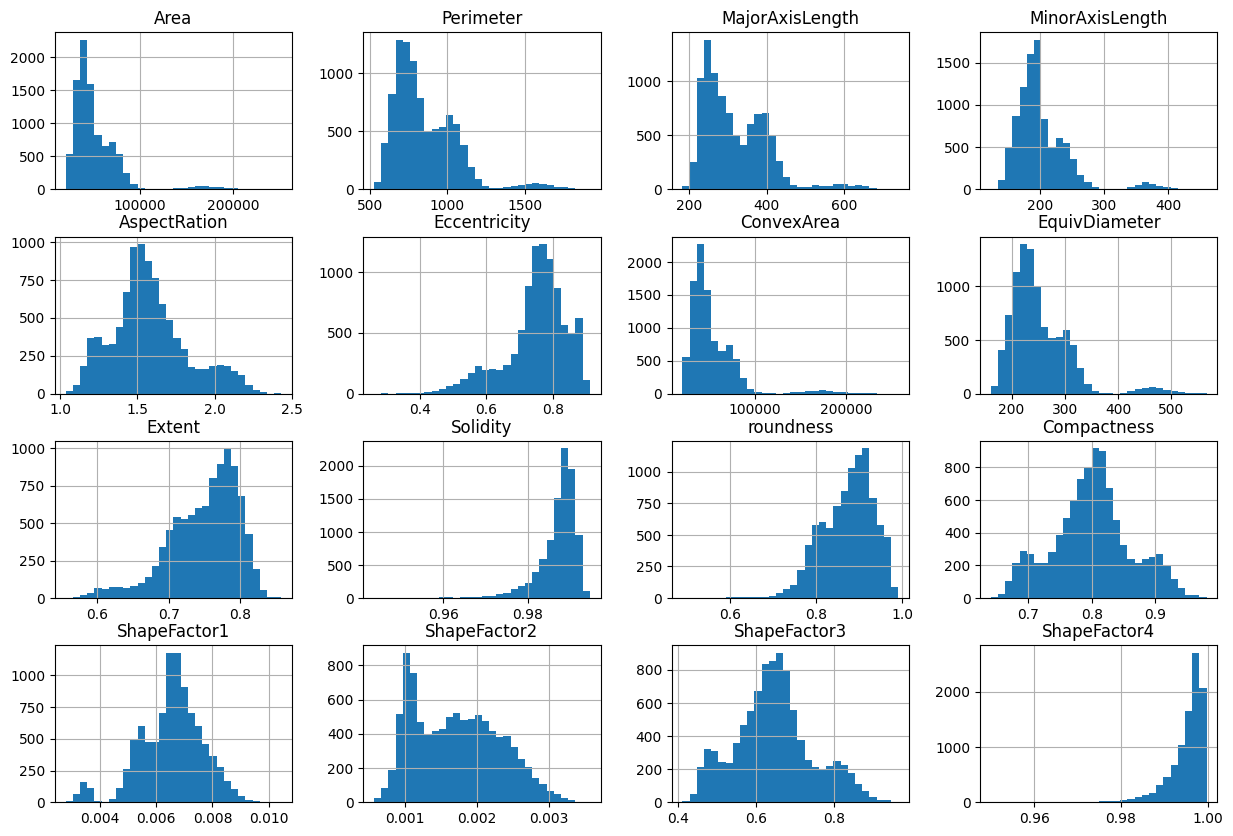

In [85]:
dataMain.hist(bins=30, figsize=(15, 10))
plt.show()

## Box Plots (so much outliers again)

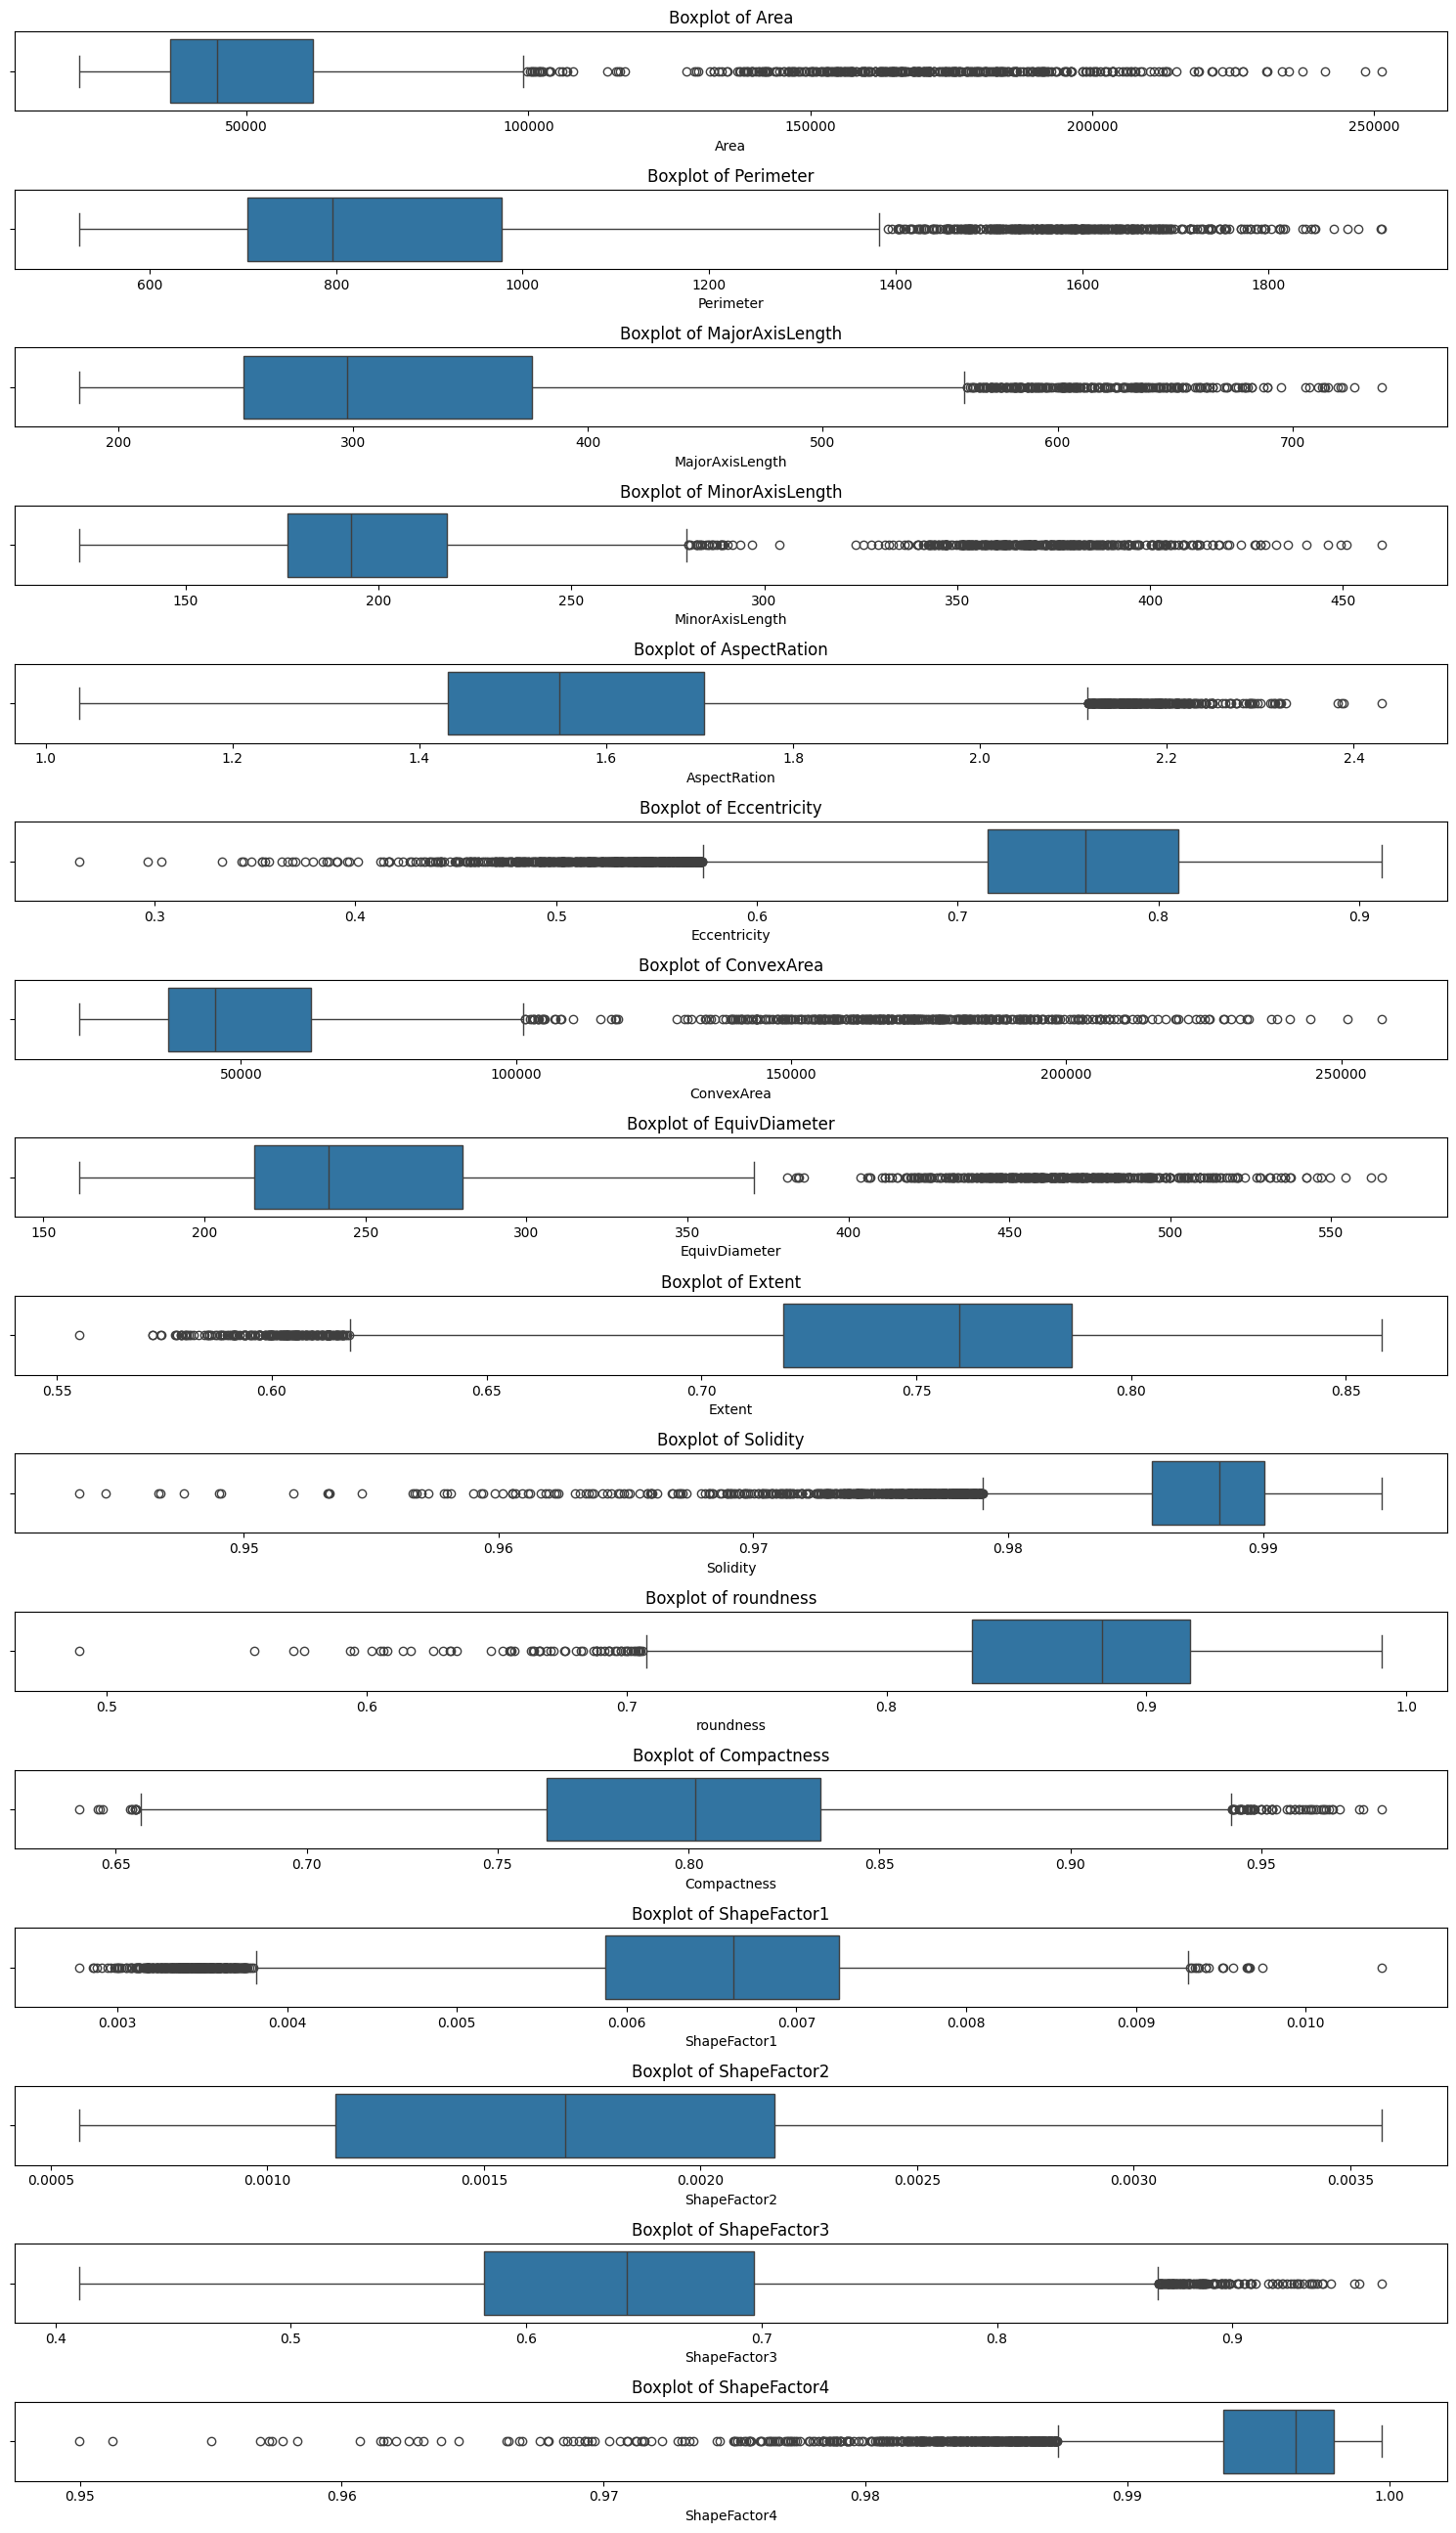

In [86]:
numeric_cols = dataMain.select_dtypes(include='number').columns

plt.figure(figsize=(15, 5 * len(numeric_cols) // 3))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataMain[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
plt.tight_layout()
plt.show()

## CLASS Distribution

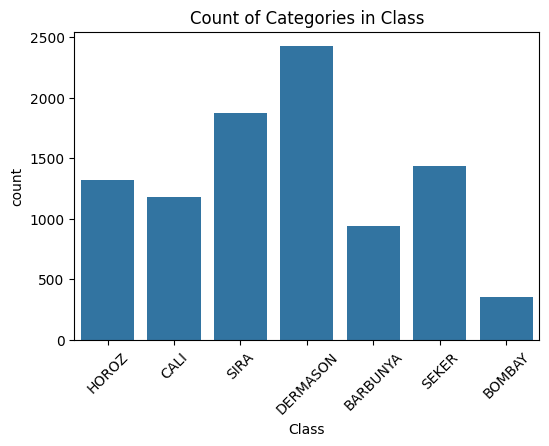

In [87]:
categorical_cols = dataMain.select_dtypes(include='object').columns

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=dataMain[col])
    plt.title(f"Count of Categories in {col}")
    plt.xticks(rotation=45)
    plt.show()

## Correlation Heatmap For Features (we have so much correlated feature that means PCA is important for us to reduce the count of feature)

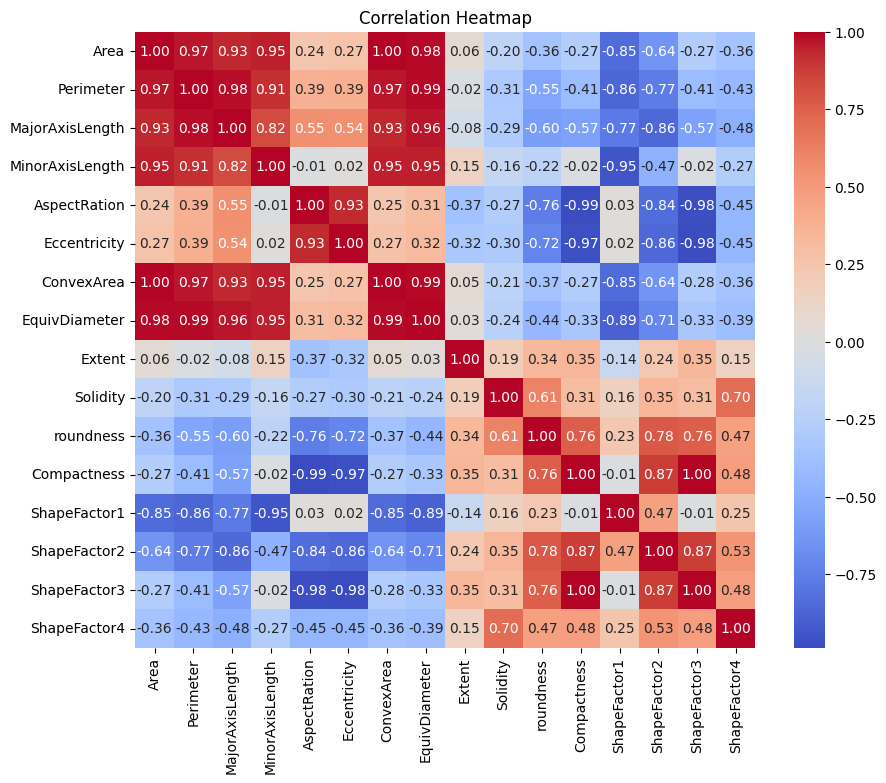

In [88]:
plt.figure(figsize=(10, 8))
sns.heatmap(dataMain.select_dtypes(include='number').corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Box plots for different Classes

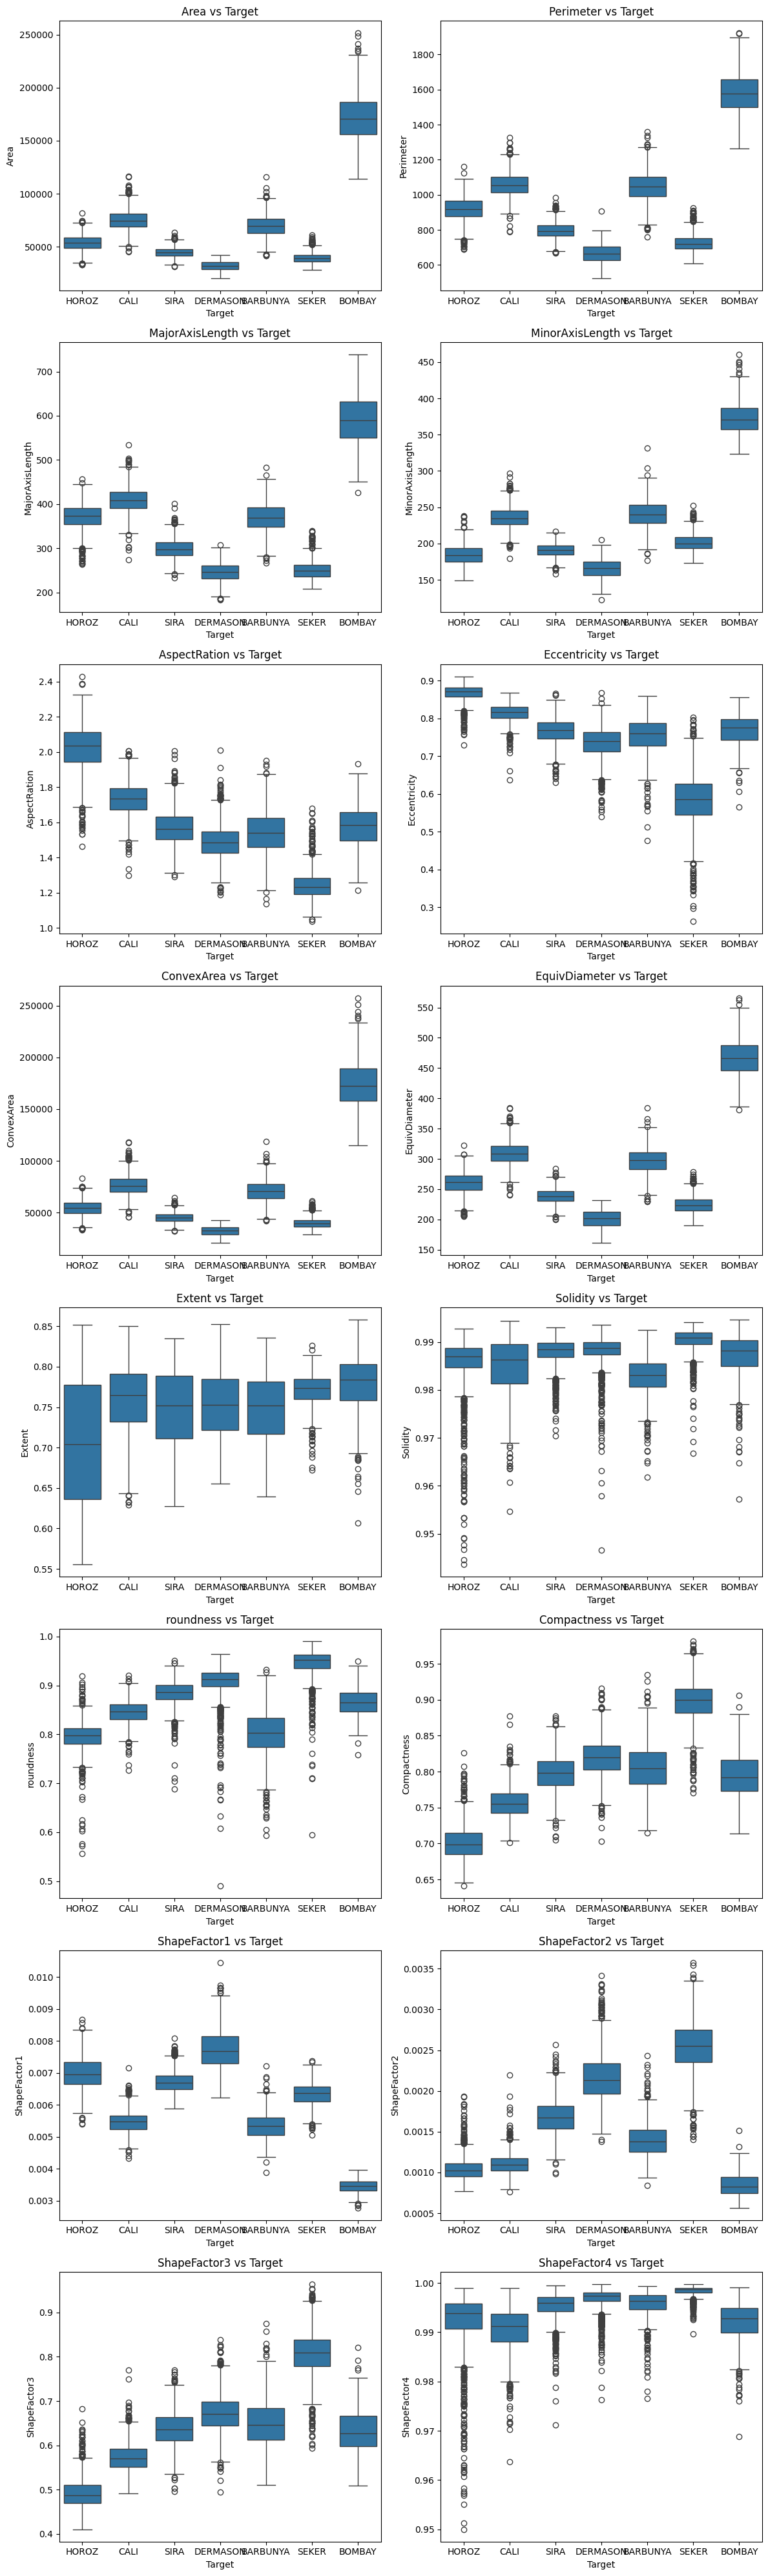

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Select numeric columns (excluding target)
numeric_cols = dataMain.select_dtypes(include='number').columns.drop('target', errors='ignore')

# Define grid size: 2 plots per row
num_plots = len(numeric_cols)
n_cols = 2
n_rows = math.ceil(num_plots / n_cols)

# Create subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows))
axes = axes.flatten()  # flatten for easy iteration

# Loop through features
for i, col in enumerate(numeric_cols):
    sns.boxplot(x='Class', y=col, data=dataMain, ax=axes[i])
    axes[i].set_title(f"{col} vs Target")
    axes[i].set_xlabel('Target')
    axes[i].set_ylabel(col)

# Hide any empty subplots (if odd number of features)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Check if some inconsistency in classes (we have nan class and for this type of rows all features are NaN too)

In [91]:
dataMain["Class"].unique()

array(['HOROZ', 'CALI', 'SIRA', 'DERMASON', 'BARBUNYA', 'SEKER', nan,
       'BOMBAY'], dtype=object)

## Checking Outliers

In [92]:
for col in numeric_cols:
    Q1 = dataMain[col].quantile(0.25)
    Q3 = dataMain[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((dataMain[col] < lower) | (dataMain[col] > upper)).sum()
    print(f"{col}: {outlier_count} outliers")

Area: 379 outliers
Perimeter: 340 outliers
MajorAxisLength: 250 outliers
MinorAxisLength: 384 outliers
AspectRation: 327 outliers
Eccentricity: 604 outliers
ConvexArea: 377 outliers
EquivDiameter: 359 outliers
Extent: 194 outliers
Solidity: 547 outliers
roundness: 61 outliers
Compactness: 74 outliers
ShapeFactor1: 365 outliers
ShapeFactor2: 0 outliers
ShapeFactor3: 136 outliers
ShapeFactor4: 530 outliers


# Additional Data

## Columns (the order is different from main data in addition to this additional data has 3 feature which is not in main data and does not have 2 feature which is in main data)

In [93]:
dataAdd.columns

Index(['Area', 'Perimeter', 'Length', 'Width', 'AspectRation', 'Class',
       'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness',
       'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3',
       'ShapeFactor4', 'Eccentricity', 'Color'],
      dtype='object')

## One feature is extra

In [94]:
dataAdd.shape

(4099, 18)

## Color feature is not in main data and in additional data there is no data for color too ??

In [95]:
dataAdd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4099 entries, 0 to 4098
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area           4077 non-null   float64
 1   Perimeter      4084 non-null   float64
 2   Length         4084 non-null   float64
 3   Width          4084 non-null   float64
 4   AspectRation   4084 non-null   float64
 5   Class          4084 non-null   object 
 6   ConvexArea     4084 non-null   float64
 7   EquivDiameter  4084 non-null   float64
 8   Extent         4084 non-null   float64
 9   Solidity       4084 non-null   float64
 10  roundness      4084 non-null   float64
 11  Compactness    4084 non-null   float64
 12  ShapeFactor1   4084 non-null   float64
 13  ShapeFactor2   4084 non-null   float64
 14  ShapeFactor3   4084 non-null   float64
 15  ShapeFactor4   4084 non-null   float64
 16  Eccentricity   4084 non-null   float64
 17  Color          0 non-null      float64
dtypes: float

# Before make any operation I want to make column order same with main data (my approach is if both of them have the same feature make order in alphabetical they don't I move them to back.)

In [96]:
listOfColumns = dataMain.columns.to_list()
listOfColumns

['Area',
 'Perimeter',
 'MajorAxisLength',
 'MinorAxisLength',
 'AspectRation',
 'Eccentricity',
 'ConvexArea',
 'EquivDiameter',
 'Extent',
 'Solidity',
 'roundness',
 'Compactness',
 'ShapeFactor1',
 'ShapeFactor2',
 'ShapeFactor3',
 'ShapeFactor4',
 'Class']

In [97]:
list(dataAdd.columns)

['Area',
 'Perimeter',
 'Length',
 'Width',
 'AspectRation',
 'Class',
 'ConvexArea',
 'EquivDiameter',
 'Extent',
 'Solidity',
 'roundness',
 'Compactness',
 'ShapeFactor1',
 'ShapeFactor2',
 'ShapeFactor3',
 'ShapeFactor4',
 'Eccentricity',
 'Color']

In [98]:
rename = {
    'Length': 'MajorAxisLength',
    'Width': 'MinorAxisLength'
}

dataAdd = dataAdd.rename(columns=rename)

def align_columns_by_alphabet(df1: pd.DataFrame, df2: pd.DataFrame):
    common_cols = sorted(set(df1.columns).intersection(df2.columns))
    unique_df1 = sorted(set(df1.columns) - set(df2.columns))
    unique_df2 = sorted(set(df2.columns) - set(df1.columns))

    order_dict_df1 = {col: i for i, col in enumerate(common_cols + unique_df1)}
    order_dict_df2 = {col: i for i, col in enumerate(common_cols + unique_df2)}

    df1_ordered = df1[[col for col in order_dict_df1.keys() if col in df1.columns]]
    df2_ordered = df2[[col for col in order_dict_df2.keys() if col in df2.columns]]

    return df1_ordered, df2_ordered, order_dict_df1, order_dict_df2

dataMain, dataAdd, dictMain, dictAdd = align_columns_by_alphabet(dataMain, dataAdd)

In [99]:
dictMain

{'Area': 0,
 'AspectRation': 1,
 'Class': 2,
 'Compactness': 3,
 'ConvexArea': 4,
 'Eccentricity': 5,
 'EquivDiameter': 6,
 'Extent': 7,
 'MajorAxisLength': 8,
 'MinorAxisLength': 9,
 'Perimeter': 10,
 'ShapeFactor1': 11,
 'ShapeFactor2': 12,
 'ShapeFactor3': 13,
 'ShapeFactor4': 14,
 'Solidity': 15,
 'roundness': 16}

In [100]:
dictAdd

{'Area': 0,
 'AspectRation': 1,
 'Class': 2,
 'Compactness': 3,
 'ConvexArea': 4,
 'Eccentricity': 5,
 'EquivDiameter': 6,
 'Extent': 7,
 'MajorAxisLength': 8,
 'MinorAxisLength': 9,
 'Perimeter': 10,
 'ShapeFactor1': 11,
 'ShapeFactor2': 12,
 'ShapeFactor3': 13,
 'ShapeFactor4': 14,
 'Solidity': 15,
 'roundness': 16,
 'Color': 17}

# Color column is not in the main dataset and all values is NaN for additional data as well

In [101]:
print("nan values :",dataAdd["Color"].isna().sum())
print("shape :" ,dataAdd.shape[0])

nan values : 4099
shape : 4099


In [102]:
dataAdd = dataAdd.drop("Color", axis=1)

## Checking the NaN values after droping Color feature

In [103]:
dataAdd.isna().sum()

,0
Area,22
AspectRation,15
Class,15
Compactness,15
ConvexArea,15
Eccentricity,15
EquivDiameter,15
Extent,15
MajorAxisLength,15
MinorAxisLength,15


## Checking duplicate Rows

In [104]:
print("Duplicate Rows:", dataAdd.duplicated().sum())

Duplicate Rows: 21


## Head and Tail

In [105]:
dataAdd.head()

,Area,AspectRation,Class,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
0,28734.0,1.097356,SEKER,0.953861,29172.0,0.411785,191.272751,0.783968,200.524796,182.734419,638.018,0.006979,0.003564,0.909851,0.998430,0.984986,0.887034
1,30140.0,1.060798,SEKER,0.970516,30417.0,0.333680,195.896503,0.773098,201.847882,190.279279,620.134,0.006697,0.003665,0.941900,0.999166,0.990893,0.984877
2,30279.0,1.171067,SEKER,0.923726,30600.0,0.520401,196.347702,0.775688,212.560556,181.510182,634.927,0.007020,0.003153,0.853270,0.999236,0.989510,0.943852
3,30477.0,1.146768,SEKER,0.933374,30970.0,0.489478,196.988633,0.762402,211.050155,184.039050,670.033,0.006925,0.003242,0.871186,0.999049,0.984081,0.853080
4,30519.0,1.165591,SEKER,0.925480,30847.0,0.513760,197.124320,0.770682,212.996755,182.737204,629.727,0.006979,0.003158,0.856514,0.998345,0.989367,0.967109


In [106]:
dataAdd.tail()

,Area,AspectRation,Class,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
4094,41962.0,1.537446,DERMASON,0.805745,42349.0,0.759567,231.144279,0.764711,286.870391,186.588937,755.945,0.006836,0.001777,0.649224,0.998147,0.990862,0.922753
4095,41966.0,1.399385,DERMASON,0.845148,42250.0,0.699534,231.155296,0.751998,273.508678,195.449153,746.121,0.006517,0.002051,0.714275,0.999546,0.993278,0.947303
4096,41995.0,1.506285,DERMASON,0.813999,42477.0,0.747835,231.235150,0.732514,284.073178,188.591957,765.763,0.006764,0.001832,0.662594,0.998055,0.988653,0.899951
4097,42023.0,1.390297,DERMASON,0.847413,42365.0,0.694730,231.312225,0.795348,272.962686,196.334047,746.715,0.006496,0.002066,0.718109,0.998386,0.991927,0.947081
4098,42139.0,1.472582,DERMASON,0.822730,42569.0,0.734065,231.631261,0.729932,281.539928,191.187979,759.321,0.006681,0.001888,0.676884,0.996767,0.989899,0.918424


## Describe

In [107]:
dataAdd.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,4077.0,52930.002208,29998.073066,20548.000000,35975.000000,44468.000000,60453.000000,254616.000000
AspectRation,4084.0,1.589575,0.249059,1.024868,1.434815,1.555313,1.711638,2.364017
Compactness,4084.0,0.798314,0.061716,0.648762,0.761274,0.800318,0.833422,0.987303
ConvexArea,4084.0,53649.481881,30430.867309,20825.000000,36397.500000,45053.000000,61367.500000,263261.000000
Eccentricity,4084.0,0.753185,0.090946,0.218951,0.717116,0.765902,0.811584,0.906126
EquivDiameter,4084.0,252.517023,60.270739,161.748342,214.065899,238.011777,277.467724,569.374358
Extent,4084.0,0.749739,0.049960,0.566669,0.717193,0.759674,0.788210,0.866195
MajorAxisLength,4084.0,320.101841,87.110906,183.965251,253.073656,296.301489,376.818048,738.860154
MinorAxisLength,4084.0,201.433463,45.803529,129.576207,174.754001,191.264037,215.169957,447.418329
Perimeter,4084.0,853.726648,217.805939,524.736000,701.503250,793.375500,972.722750,1985.370000


## Histogram to see distribution of data (we have a lot of skew)

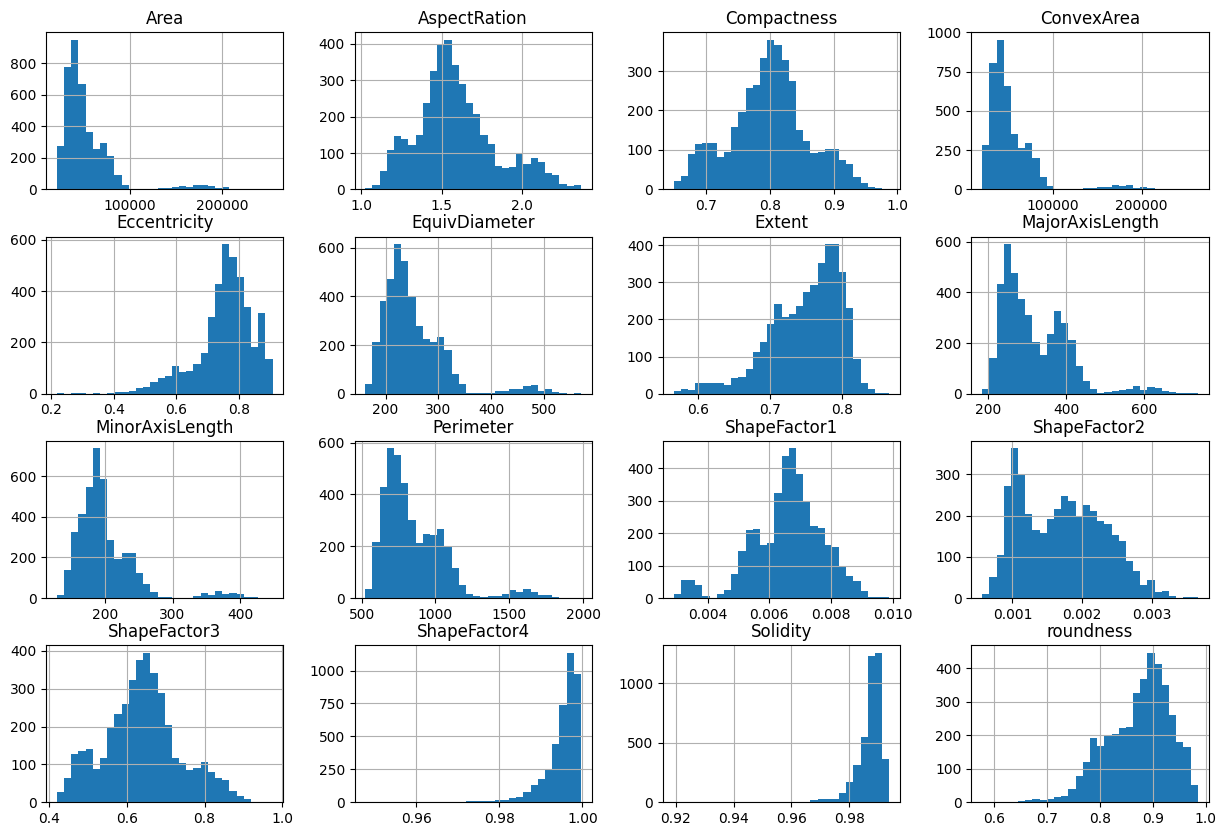

In [108]:
dataAdd.hist(bins=30, figsize=(15, 10))
plt.show()

## Box plot

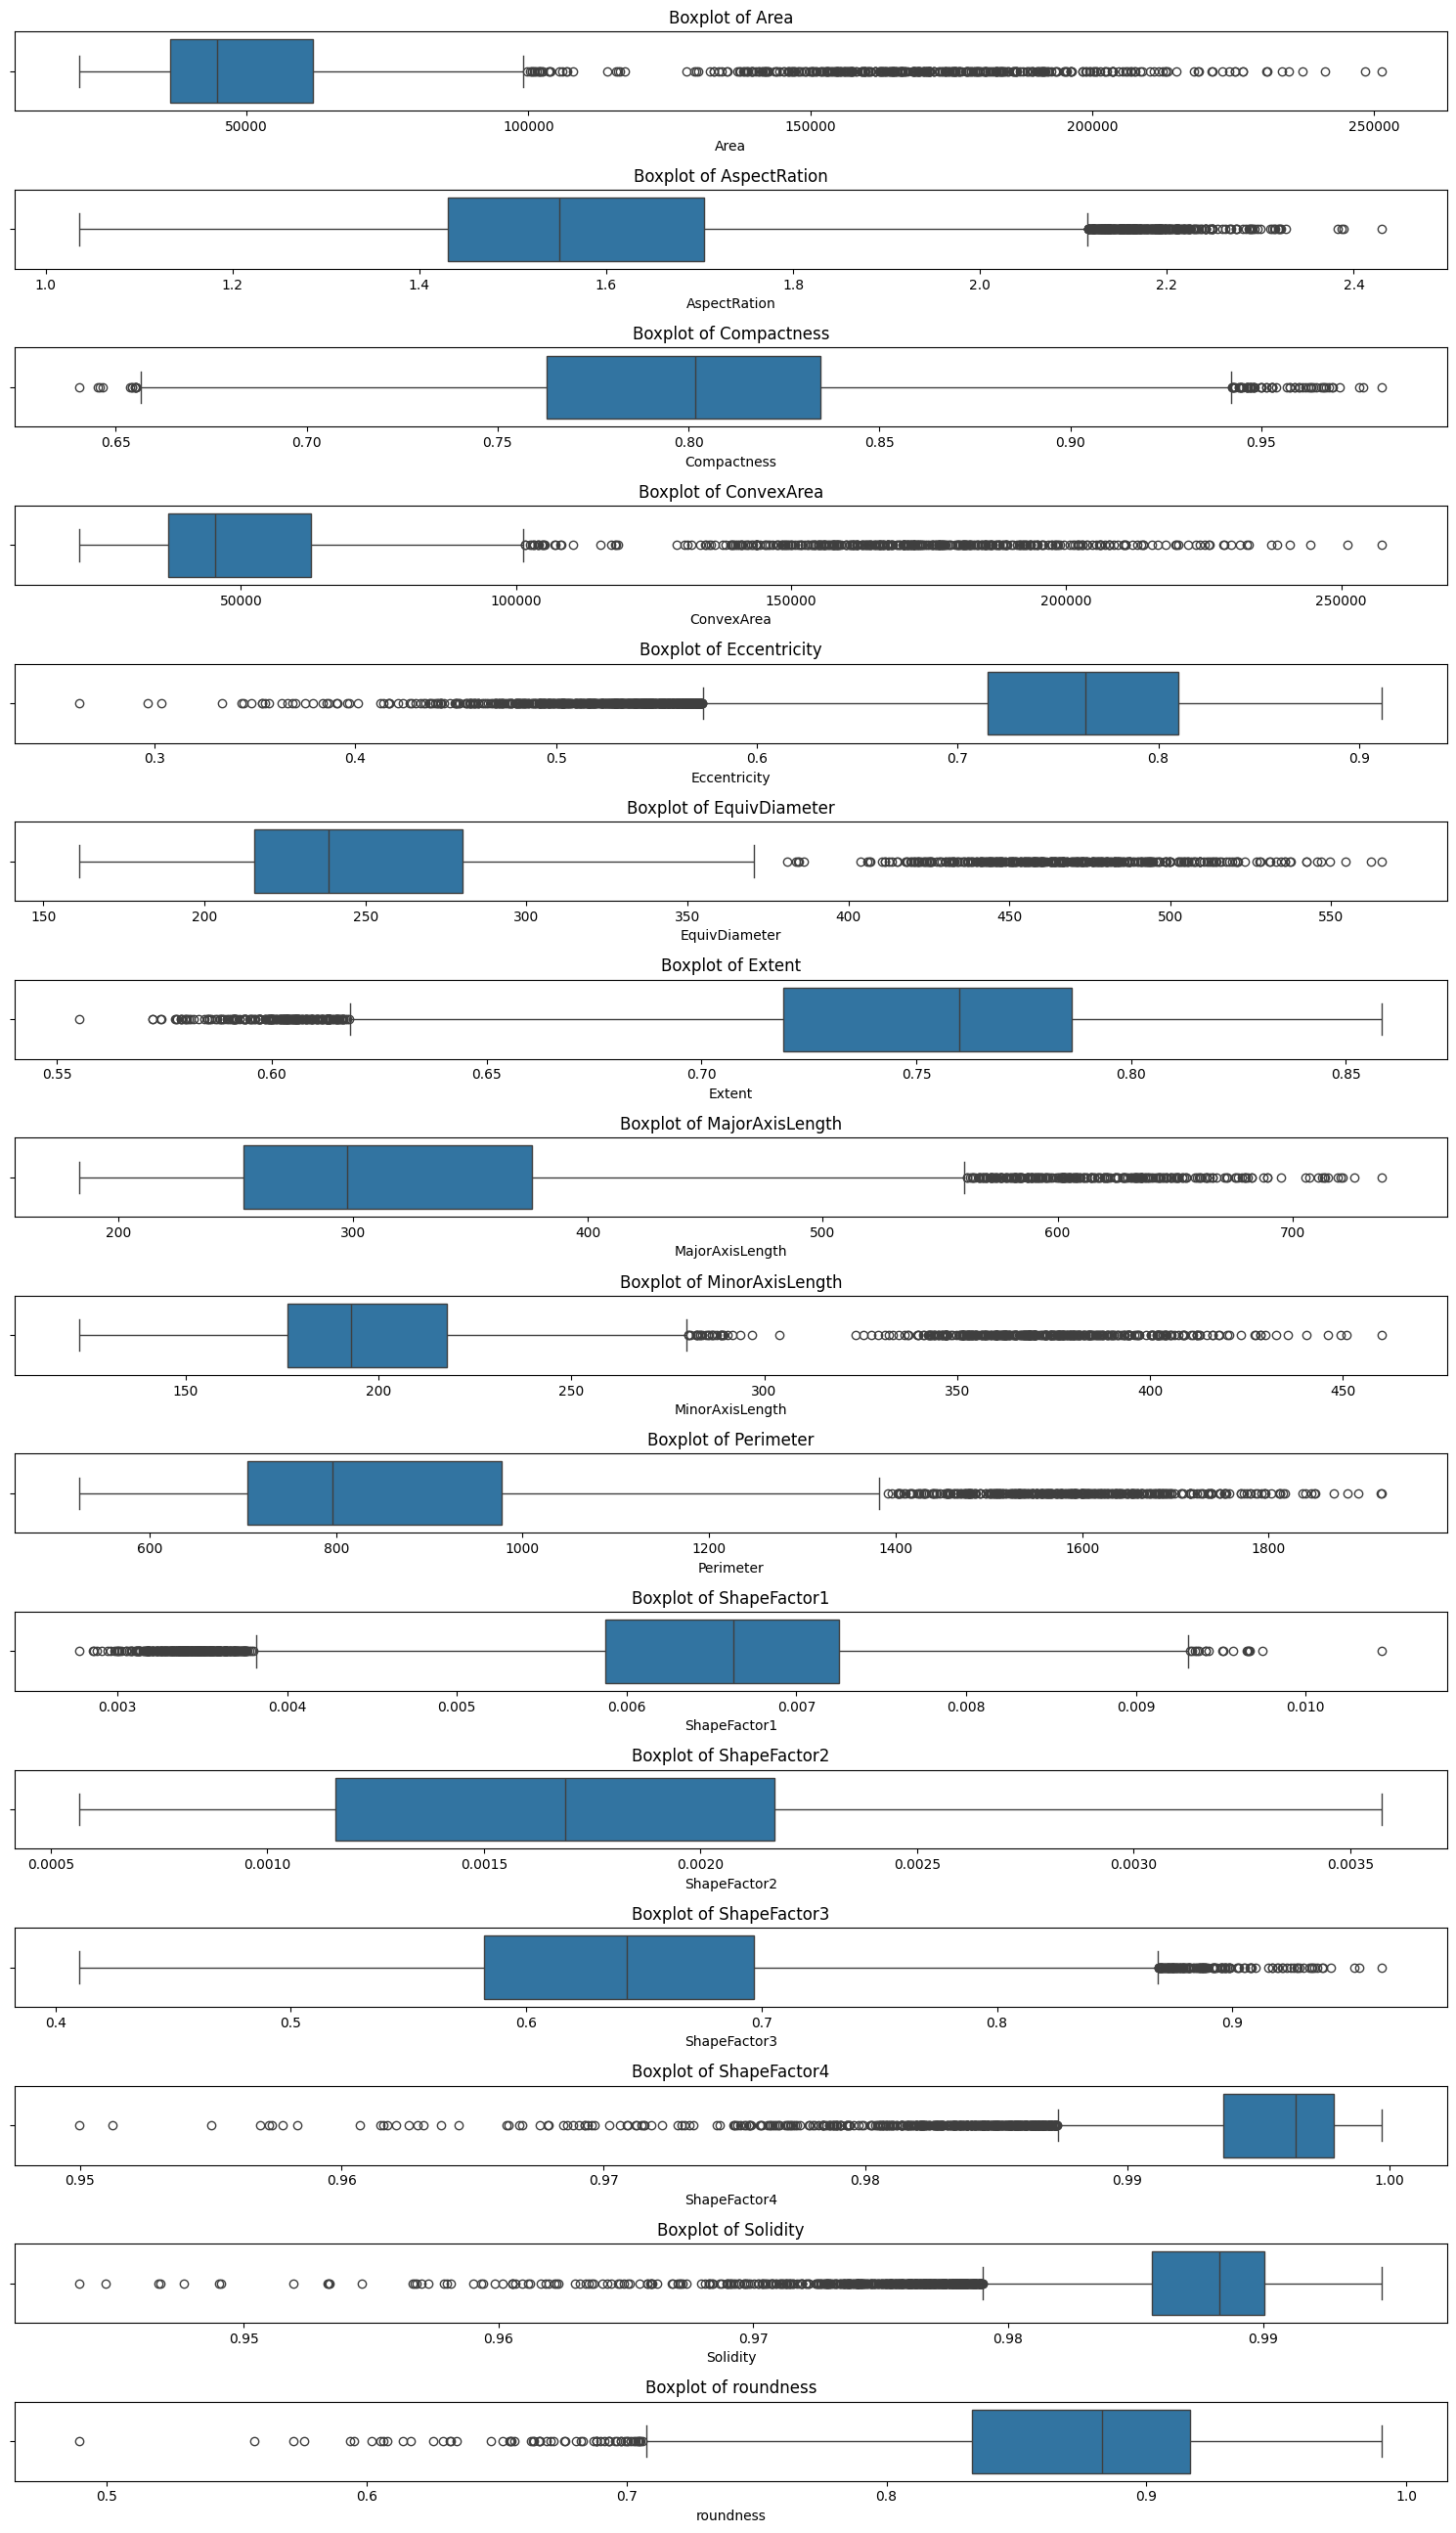

In [109]:
numeric_cols = dataAdd.select_dtypes(include='number').columns

plt.figure(figsize=(15, 5 * len(numeric_cols) // 3))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataMain[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
plt.tight_layout()
plt.show()

## Distribution of Class

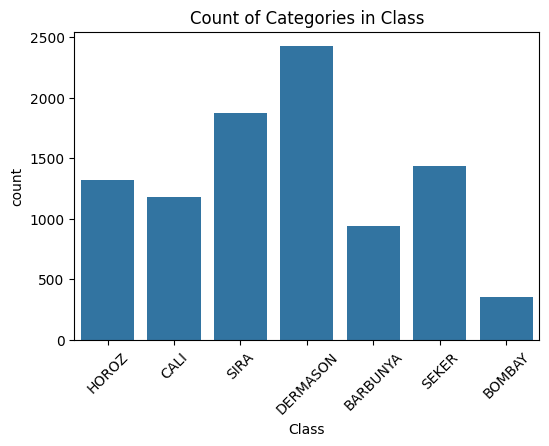

In [110]:
categorical_cols = dataAdd.select_dtypes(include='object').columns

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=dataMain[col])
    plt.title(f"Count of Categories in {col}")
    plt.xticks(rotation=45)
    plt.show()

# HeatMap to see correlation between features

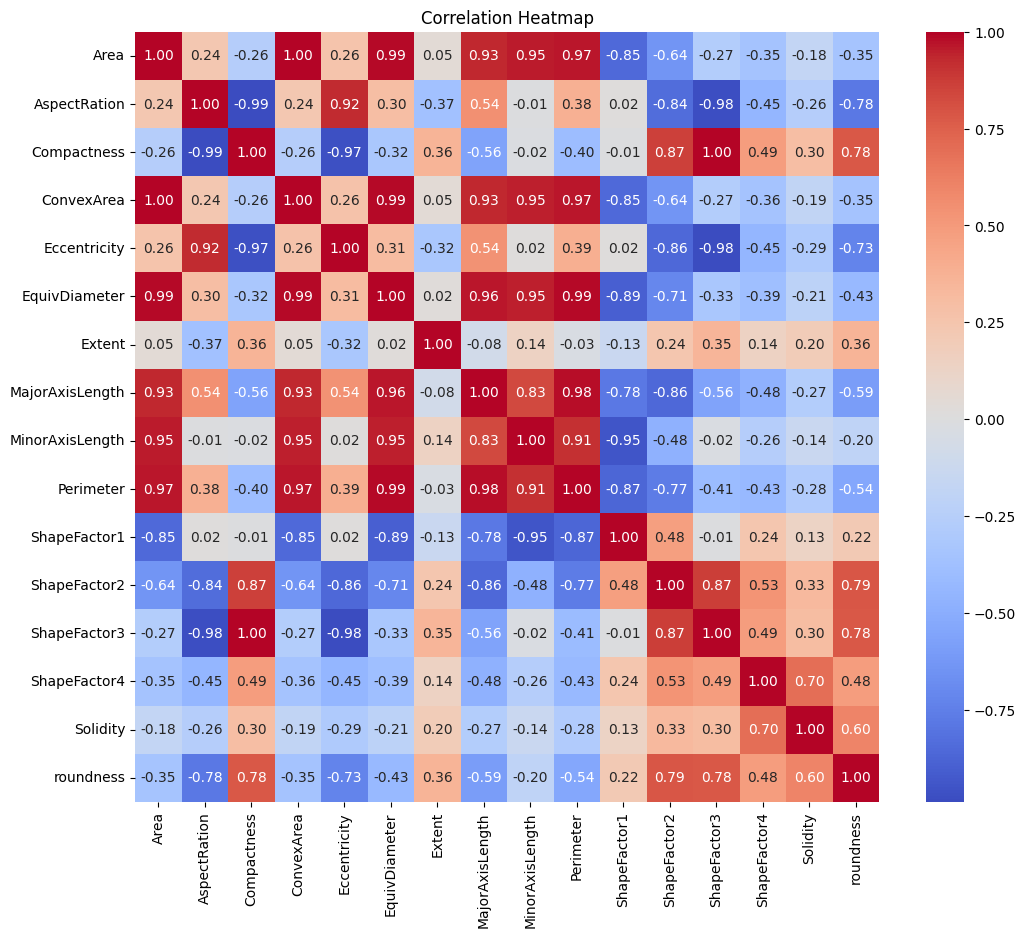

In [111]:
plt.figure(figsize=(12, 10))
sns.heatmap(dataAdd.select_dtypes(include='number').corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Box plot for every different Class Variables

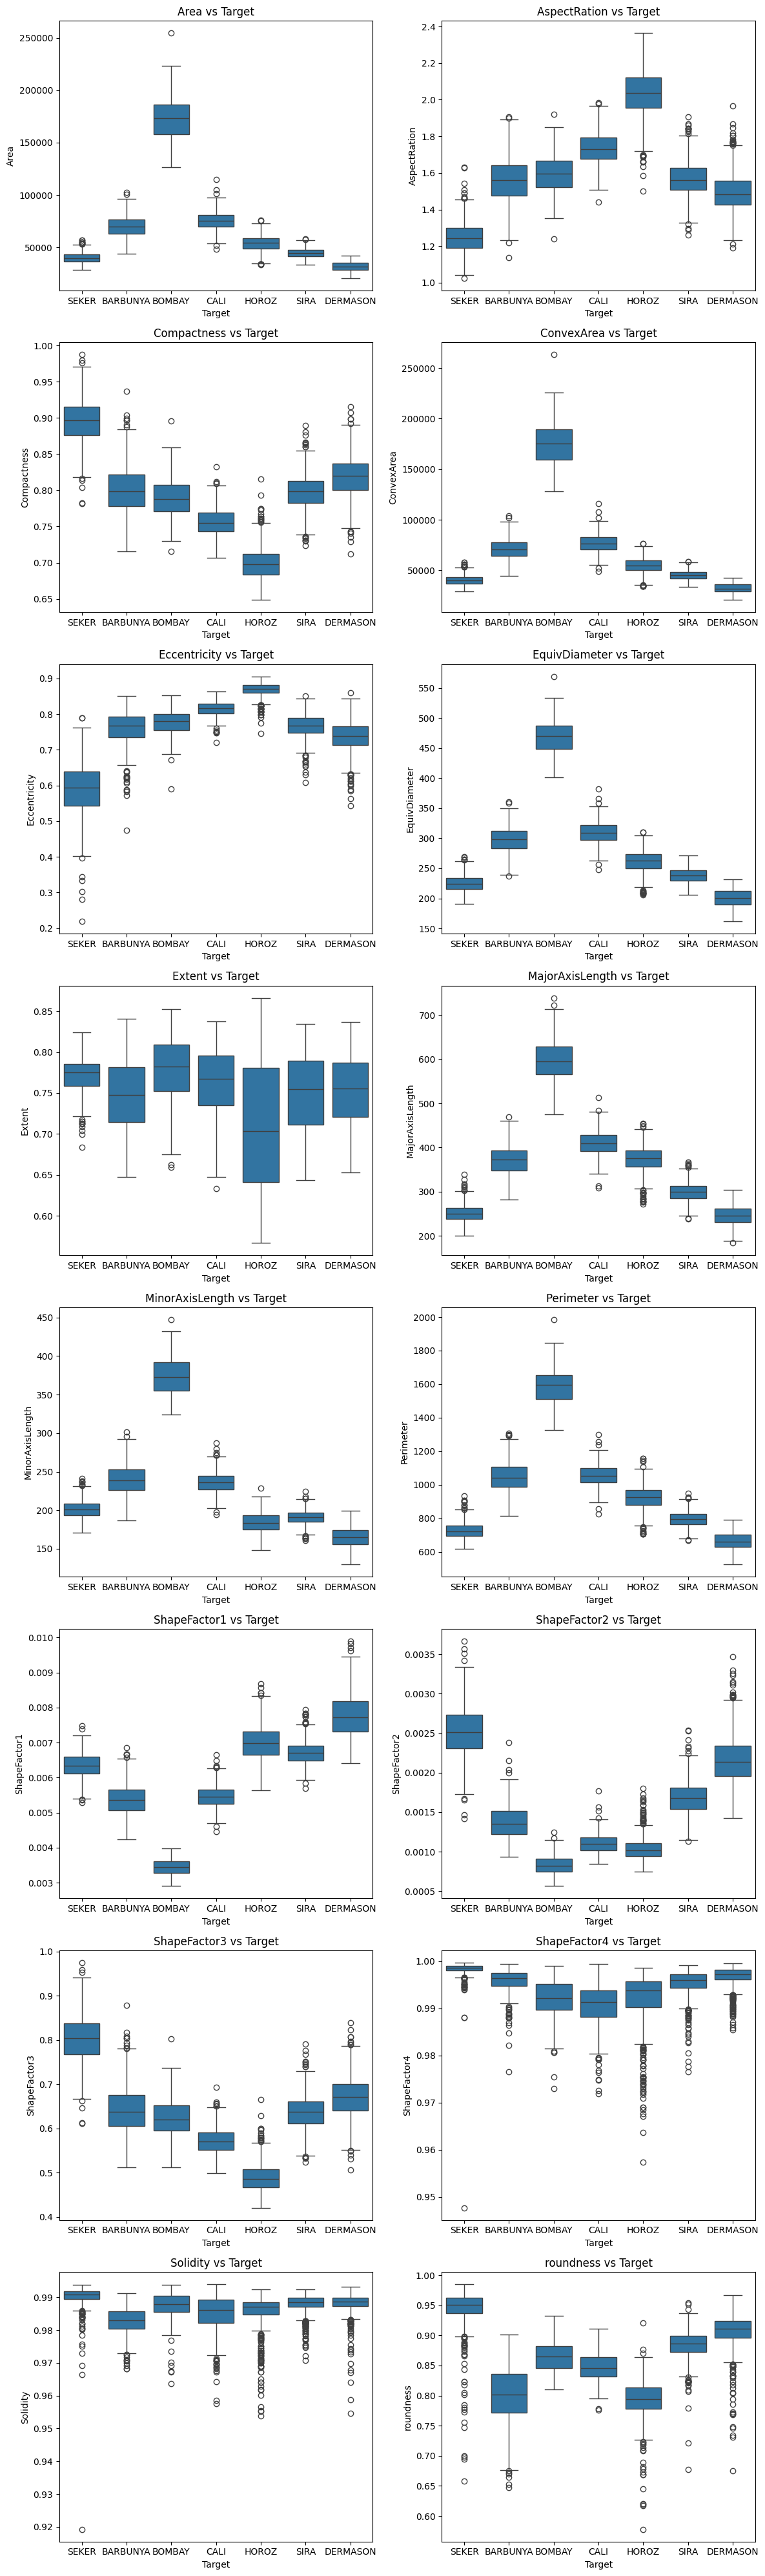

In [113]:
num_plots = len(numeric_cols)
n_cols = 2
n_rows = math.ceil(num_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(x='Class', y=col, data=dataAdd, ax=axes[i])
    axes[i].set_title(f"{col} vs Target")
    axes[i].set_xlabel('Target')
    axes[i].set_ylabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Checking class to if any inconsistent data

In [114]:
dataAdd["Class"].unique()

array(['SEKER', nan, 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA',
       'DERMASON'], dtype=object)

## Checking outliers

In [115]:
for col in numeric_cols:
    Q1 = dataAdd[col].quantile(0.25)
    Q3 = dataAdd[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = ((dataAdd[col] < lower) | (dataAdd[col] > upper)).sum()
    print(f"{col}: {outlier_count} outliers")

Area: 172 outliers
AspectRation: 145 outliers
Compactness: 32 outliers
ConvexArea: 171 outliers
Eccentricity: 234 outliers
EquivDiameter: 167 outliers
Extent: 71 outliers
MajorAxisLength: 129 outliers
MinorAxisLength: 180 outliers
Perimeter: 162 outliers
ShapeFactor1: 172 outliers
ShapeFactor2: 0 outliers
ShapeFactor3: 56 outliers
ShapeFactor4: 230 outliers
Solidity: 223 outliers
roundness: 33 outliers


# Dataset Integration

## No mismatched data type

### Data Integration Explanation

The two datasets (`dataMain` and `dataAdd`) contain similar observations with matching column structures.  
To create a unified dataset, the tables were combined vertically using `pd.concat()`.  
This approach appends the rows of one dataset to the other, preserving all existing features.  

Before concatenation, the column names and data types of both datasets were reviewed to ensure consistency.  
This alignment step prevents potential mismatches or missing columns after integration.  
After combining, the resulting dataset was inspected to verify that the total number of rows and columns was as expected and that no new missing values were introduced.

In [116]:
dataMain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9565 entries, 0 to 9564
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             9509 non-null   float64
 1   AspectRation     9527 non-null   float64
 2   Class            9527 non-null   object 
 3   Compactness      9527 non-null   float64
 4   ConvexArea       9527 non-null   float64
 5   Eccentricity     9527 non-null   float64
 6   EquivDiameter    9527 non-null   float64
 7   Extent           9527 non-null   float64
 8   MajorAxisLength  9527 non-null   float64
 9   MinorAxisLength  9527 non-null   float64
 10  Perimeter        9527 non-null   float64
 11  ShapeFactor1     9527 non-null   float64
 12  ShapeFactor2     9527 non-null   float64
 13  ShapeFactor3     9527 non-null   float64
 14  ShapeFactor4     9527 non-null   float64
 15  Solidity         9478 non-null   float64
 16  roundness        9527 non-null   float64
dtypes: float64(16)

In [117]:
dataAdd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4099 entries, 0 to 4098
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             4077 non-null   float64
 1   AspectRation     4084 non-null   float64
 2   Class            4084 non-null   object 
 3   Compactness      4084 non-null   float64
 4   ConvexArea       4084 non-null   float64
 5   Eccentricity     4084 non-null   float64
 6   EquivDiameter    4084 non-null   float64
 7   Extent           4084 non-null   float64
 8   MajorAxisLength  4084 non-null   float64
 9   MinorAxisLength  4084 non-null   float64
 10  Perimeter        4084 non-null   float64
 11  ShapeFactor1     4084 non-null   float64
 12  ShapeFactor2     4084 non-null   float64
 13  ShapeFactor3     4084 non-null   float64
 14  ShapeFactor4     4084 non-null   float64
 15  Solidity         4084 non-null   float64
 16  roundness        4084 non-null   float64
dtypes: float64(16)

In [118]:
data = pd.concat([dataMain, dataAdd], ignore_index=True)
data.tail()

,Area,AspectRation,Class,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
13659,41962.0,1.537446,DERMASON,0.805745,42349.0,0.759567,231.144279,0.764711,286.870391,186.588937,755.945,0.006836,0.001777,0.649224,0.998147,0.990862,0.922753
13660,41966.0,1.399385,DERMASON,0.845148,42250.0,0.699534,231.155296,0.751998,273.508678,195.449153,746.121,0.006517,0.002051,0.714275,0.999546,0.993278,0.947303
13661,41995.0,1.506285,DERMASON,0.813999,42477.0,0.747835,231.235150,0.732514,284.073178,188.591957,765.763,0.006764,0.001832,0.662594,0.998055,0.988653,0.899951
13662,42023.0,1.390297,DERMASON,0.847413,42365.0,0.694730,231.312225,0.795348,272.962686,196.334047,746.715,0.006496,0.002066,0.718109,0.998386,0.991927,0.947081
13663,42139.0,1.472582,DERMASON,0.822730,42569.0,0.734065,231.631261,0.729932,281.539928,191.187979,759.321,0.006681,0.001888,0.676884,0.996767,0.989899,0.918424


In [119]:
data.duplicated().sum()

np.int64(119)

In [120]:
duplicated_rows = data[data.duplicated(keep=False)]
print(f"Number of duplicated rows: {len(duplicated_rows)}")
display(duplicated_rows.head())

Number of duplicated rows: 187


,Area,AspectRation,Class,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
176,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
251,48623.0,2.075956,HOROZ,0.689943,49603.0,0.876333,248.814643,0.591025,360.630734,173.717872,896.599,0.007417,0.001037,0.476021,0.988200,0.980243,0.760073
264,51515.0,2.149596,HOROZ,0.681172,52000.0,0.885204,256.107273,0.804294,375.980183,174.907355,896.279,0.007298,0.000969,0.463996,0.997403,0.990673,0.805855
332,33518.0,1.798842,HOROZ,0.744251,34023.0,0.831240,206.582775,0.808383,277.571399,154.305581,702.956,0.008281,0.001567,0.553909,0.996396,0.985157,0.852377


# Data Preprocess

## Data Preprocessing Summary

Missing values were handled using group-wise mean imputation to preserve class-level distributions.  
Outliers were detected and removed using the interquartile range (IQR) method to reduce noise.  
Numerical features were standardized using the StandardScaler, transforming them to have zero mean and unit variance.  
This scaling ensures that all features contribute equally to distance-based analyses such as PCA or clustering.

## Handling NaNs and duplicates

In [121]:
feature_cols = [col for col in data.columns if col != 'Class']
original_shape = data.shape
data = data.dropna(how='all', subset=feature_cols)
new_shape = data.shape
print(f"Original shape: {original_shape}")
print(f"New shape after dropping rows with all NaN features: {new_shape}")
print("\nMissing values after operation:")
display(data.isna().sum())

Original shape: (13664, 17)
New shape after dropping rows with all NaN features: (13611, 17)

Missing values after operation:


,0
Area,25
AspectRation,0
Class,0
Compactness,0
ConvexArea,0
Eccentricity,0
EquivDiameter,0
Extent,0
MajorAxisLength,0
MinorAxisLength,0


In [122]:
print('\nDuplicate rows in combined dataset:', data.duplicated().sum())


Duplicate rows in combined dataset: 67


In [123]:
duplicated_rows = data[data.duplicated(keep=False)]
print(f"Number of duplicated rows: {len(duplicated_rows)}")
display(duplicated_rows.head())

Number of duplicated rows: 134


,Area,AspectRation,Class,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
251,48623.0,2.075956,HOROZ,0.689943,49603.0,0.876333,248.814643,0.591025,360.630734,173.717872,896.599,0.007417,0.001037,0.476021,0.988200,0.980243,0.760073
264,51515.0,2.149596,HOROZ,0.681172,52000.0,0.885204,256.107273,0.804294,375.980183,174.907355,896.279,0.007298,0.000969,0.463996,0.997403,0.990673,0.805855
332,33518.0,1.798842,HOROZ,0.744251,34023.0,0.831240,206.582775,0.808383,277.571399,154.305581,702.956,0.008281,0.001567,0.553909,0.996396,0.985157,0.852377
405,59105.0,1.814595,HOROZ,0.735496,60667.0,0.834448,274.326126,0.757630,372.981361,205.545240,957.363,0.006310,0.001139,0.540954,0.981612,0.974253,0.810365
414,59442.0,2.118794,HOROZ,0.682839,60289.0,0.881616,275.107079,0.732468,402.887444,190.149460,975.979,0.006778,0.000909,0.466268,0.987927,0.985951,0.784192


In [124]:
data = data.drop_duplicates()
print('\nDuplicate rows in combined dataset:', data.duplicated().sum())


Duplicate rows in combined dataset: 0


# Check nan s

In [125]:
data.isna().sum()

,0
Area,25
AspectRation,0
Class,0
Compactness,0
ConvexArea,0
Eccentricity,0
EquivDiameter,0
Extent,0
MajorAxisLength,0
MinorAxisLength,0


# Fill the NaN s with the mean of that class

In [126]:
data["Area"] = data.groupby("Class")["Area"].transform(lambda x: x.fillna(x.mean()))
data["Solidity"] = data.groupby("Class")["Solidity"].transform(lambda x: x.fillna(x.mean()))

In [127]:
data.isna().sum()

,0
Area,0
AspectRation,0
Class,0
Compactness,0
ConvexArea,0
Eccentricity,0
EquivDiameter,0
Extent,0
MajorAxisLength,0
MinorAxisLength,0


In [128]:
data.shape

(13544, 17)

## Gettin class feature to end of the df

In [129]:
other_cols = [col for col in data.columns if col != 'Class']

new_column_order = other_cols + ['Class']

data = data[new_column_order]

display(data.head())
display(data.tail())

,Area,AspectRation,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness,Class
0,53663.0,2.084254,0.690417,54314.0,0.877384,261.392145,0.638025,378.600140,181.647777,914.023,0.007055,0.000989,0.476676,0.993514,0.988014,0.807180,HOROZ
1,81701.0,1.565727,0.795576,83006.0,0.769472,322.528982,0.750053,405.402871,258.923147,1069.534,0.004962,0.001226,0.632942,0.991014,0.984278,0.897528,CALI
2,40693.0,1.619413,0.784233,41174.0,0.786565,227.622356,0.689887,290.248493,179.230720,770.418,0.007133,0.001664,0.615021,0.995973,0.988318,0.861543,SIRA
3,30835.0,1.590960,0.791385,31272.0,0.777768,198.142225,0.737485,250.374047,157.372914,663.731,0.008120,0.001965,0.626290,0.996402,0.986026,0.879568,DERMASON
4,66997.0,1.684485,0.766306,68032.0,0.804721,292.067167,0.788423,381.136300,226.262814,978.189,0.005689,0.001210,0.587225,0.989172,0.984787,0.879872,CALI


,Area,AspectRation,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness,Class
13659,41962.0,1.537446,0.805745,42349.0,0.759567,231.144279,0.764711,286.870391,186.588937,755.945,0.006836,0.001777,0.649224,0.998147,0.990862,0.922753,DERMASON
13660,41966.0,1.399385,0.845148,42250.0,0.699534,231.155296,0.751998,273.508678,195.449153,746.121,0.006517,0.002051,0.714275,0.999546,0.993278,0.947303,DERMASON
13661,41995.0,1.506285,0.813999,42477.0,0.747835,231.235150,0.732514,284.073178,188.591957,765.763,0.006764,0.001832,0.662594,0.998055,0.988653,0.899951,DERMASON
13662,42023.0,1.390297,0.847413,42365.0,0.694730,231.312225,0.795348,272.962686,196.334047,746.715,0.006496,0.002066,0.718109,0.998386,0.991927,0.947081,DERMASON
13663,42139.0,1.472582,0.822730,42569.0,0.734065,231.631261,0.729932,281.539928,191.187979,759.321,0.006681,0.001888,0.676884,0.996767,0.989899,0.918424,DERMASON


In [130]:
data = data.reset_index(drop=True)
print(data.shape)
data.tail()

(13544, 17)


,Area,AspectRation,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness,Class
13539,41962.0,1.537446,0.805745,42349.0,0.759567,231.144279,0.764711,286.870391,186.588937,755.945,0.006836,0.001777,0.649224,0.998147,0.990862,0.922753,DERMASON
13540,41966.0,1.399385,0.845148,42250.0,0.699534,231.155296,0.751998,273.508678,195.449153,746.121,0.006517,0.002051,0.714275,0.999546,0.993278,0.947303,DERMASON
13541,41995.0,1.506285,0.813999,42477.0,0.747835,231.235150,0.732514,284.073178,188.591957,765.763,0.006764,0.001832,0.662594,0.998055,0.988653,0.899951,DERMASON
13542,42023.0,1.390297,0.847413,42365.0,0.694730,231.312225,0.795348,272.962686,196.334047,746.715,0.006496,0.002066,0.718109,0.998386,0.991927,0.947081,DERMASON
13543,42139.0,1.472582,0.822730,42569.0,0.734065,231.631261,0.729932,281.539928,191.187979,759.321,0.006681,0.001888,0.676884,0.996767,0.989899,0.918424,DERMASON


## Outlier remove

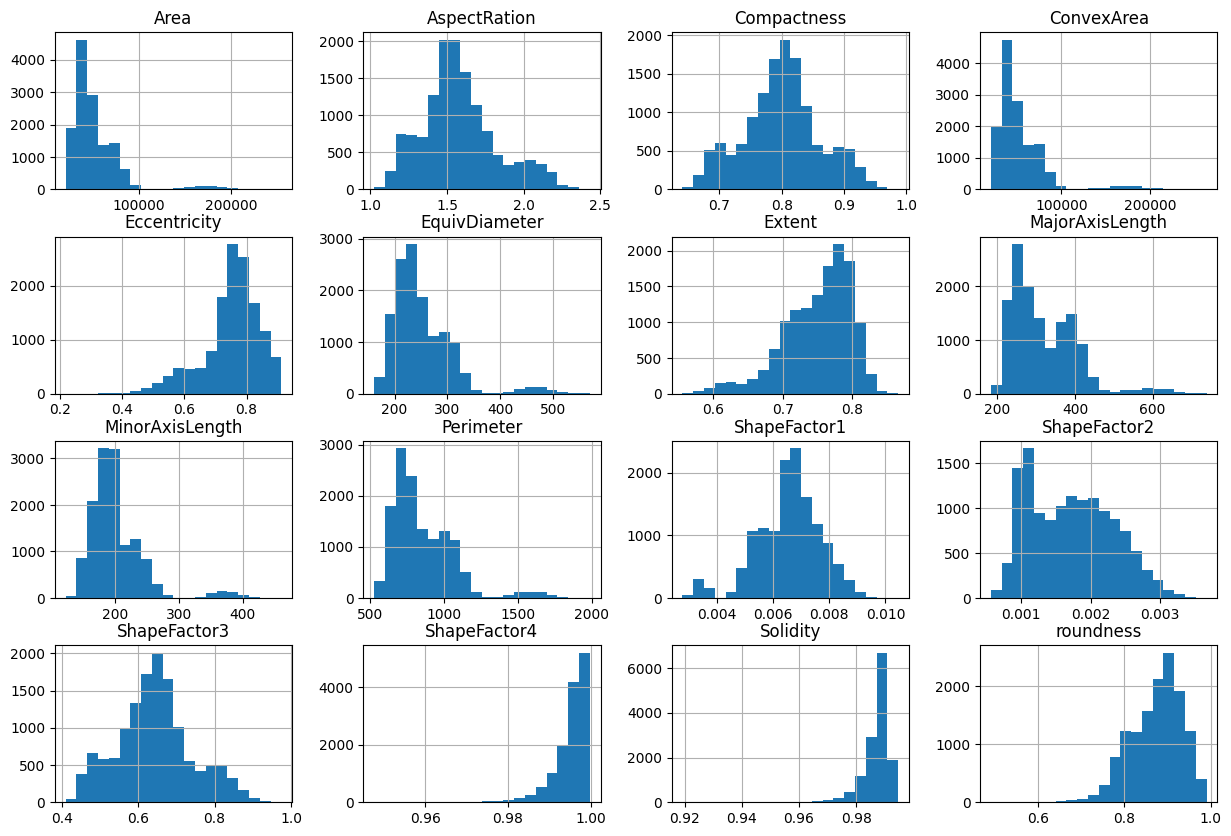

In [131]:
data[numeric_cols].hist(bins=20, figsize=(15,10))
plt.show()

# We lost 22.14% of our data so that I want to cover our data

In [132]:
mask = pd.Series(True, index=data.index)
numeric_cols = data.select_dtypes(include=['float64']).columns

for col in numeric_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask &= data[col].between(lower, upper, inclusive='both')

data_cleanMuch = data[mask]

print("Original shape:", data.shape)
print("New shape after outlier removal:", data_cleanMuch.shape)
print(f"Rows removed: {data.shape[0] - data_cleanMuch.shape[0]}")
print(f"Percentage lost: {(1 - data_cleanMuch.shape[0]/data.shape[0]) * 100:.2f}%")

Original shape: (13544, 17)
New shape after outlier removal: (10546, 17)
Rows removed: 2998
Percentage lost: 22.14%


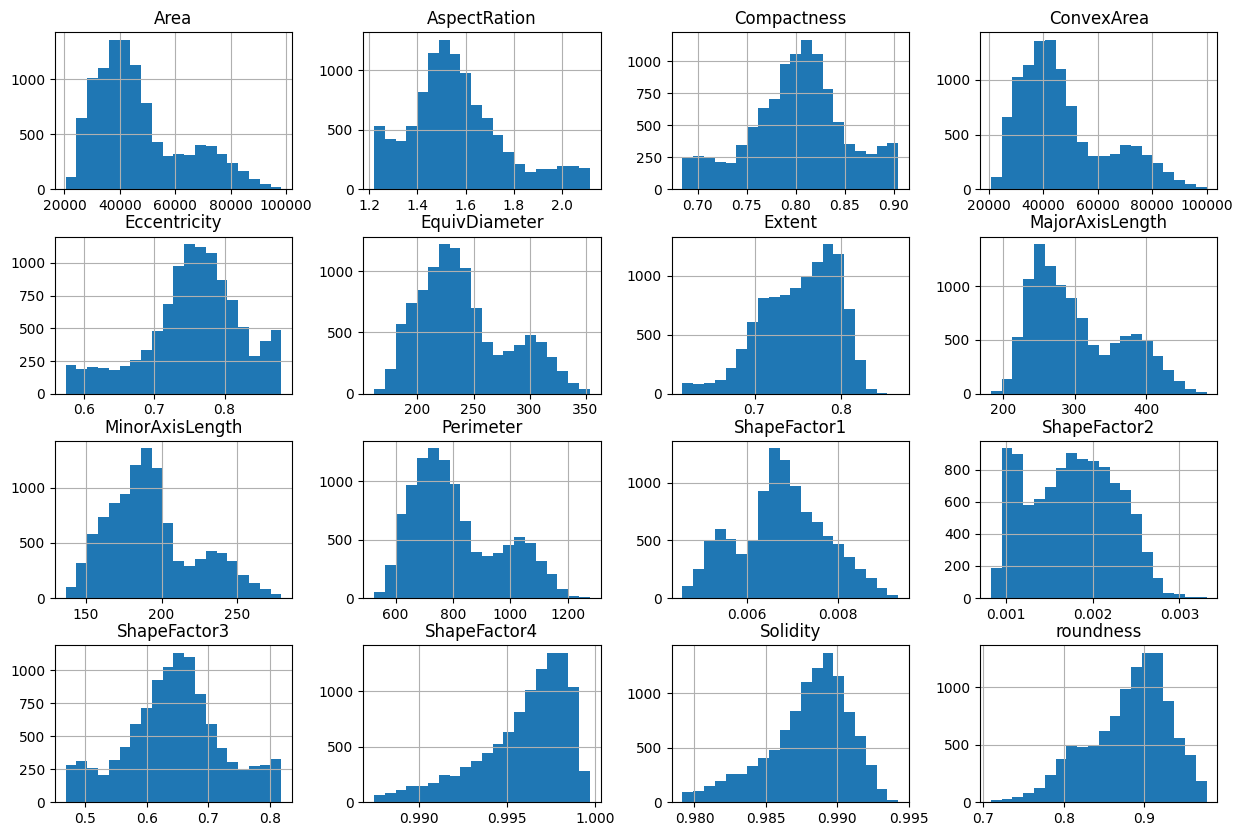

In [133]:
data_cleanMuch[numeric_cols].hist(bins=20, figsize=(15,10))
plt.show()

## And change the 1.5 to 2 so that our approache became more robust to outliers like detect lesser data points as outlier

In [134]:
mask = pd.Series(True, index=data.index)
numeric_cols = data.select_dtypes(include=['float64']).columns

for col in numeric_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 2 * IQR
    upper = Q3 + 2 * IQR

    mask &= data[col].between(lower, upper, inclusive='both')

data_cleanLow = data[mask]

print("Original shape:", data.shape)
print("New shape after outlier removal:", data_cleanLow.shape)
print(f"Rows removed: {data.shape[0] - data_cleanLow.shape[0]}")
print(f"Percentage lost: {(1 - data_cleanLow.shape[0]/data.shape[0]) * 100:.2f}%")

Original shape: (13544, 17)
New shape after outlier removal: (11935, 17)
Rows removed: 1609
Percentage lost: 11.88%


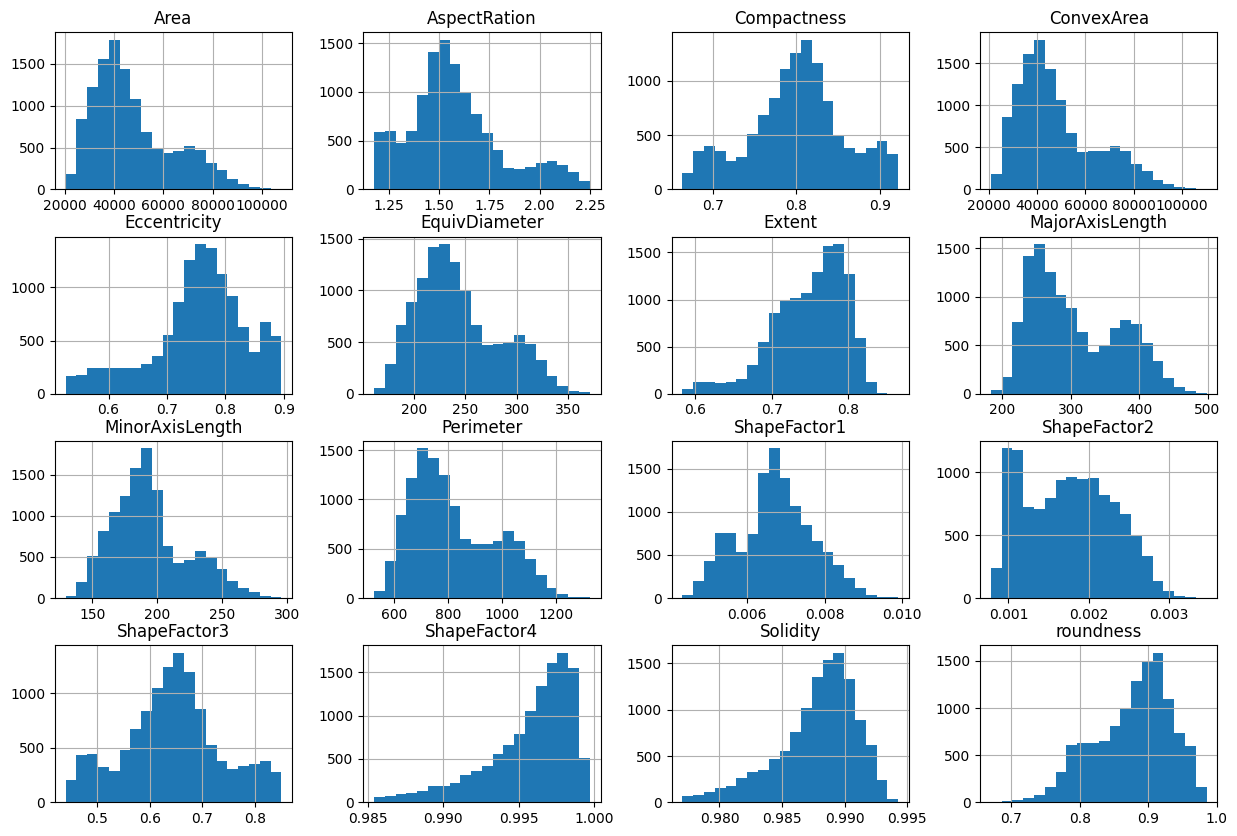

In [135]:
data_cleanLow[numeric_cols].hist(bins=20, figsize=(15,10))
plt.show()

## Data describe to select normalization method

In [136]:
dataCleaned = data_cleanLow
dataCleaned.describe()

,Area,AspectRation,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness
count,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000,11935.000000
mean,47676.579344,1.580449,0.800051,48288.446083,0.753459,243.028384,0.749555,307.058196,194.239754,819.272516,0.006725,0.001752,0.643406,0.995740,0.987798,0.877118
std,16280.560657,0.234227,0.057652,16563.760879,0.081469,40.575801,0.048004,64.855914,29.114958,155.746242,0.000961,0.000544,0.091865,0.002910,0.003182,0.055378
min,20420.000000,1.176151,0.663418,20684.000000,0.526410,161.243764,0.582947,183.601165,129.576207,524.736000,0.004328,0.000782,0.440123,0.985393,0.977044,0.669975
25%,35724.500000,1.433764,0.766436,36105.500000,0.716619,213.274110,0.718367,252.496459,173.894049,697.976000,0.006127,0.001249,0.587424,0.994325,0.986183,0.838977
50%,43432.000000,1.544676,0.803157,43963.000000,0.762163,235.149995,0.758264,290.240358,190.196448,781.342000,0.006725,0.001752,0.645061,0.996575,0.988408,0.887351
75%,56828.500000,1.691952,0.833847,57582.000000,0.806647,268.975868,0.786436,364.483356,208.528503,938.290500,0.007351,0.002176,0.695300,0.997919,0.990033,0.917664
max,107911.000000,2.248803,0.921757,110337.000000,0.895689,370.670410,0.866195,498.597779,295.713214,1326.664000,0.009897,0.003470,0.849636,0.999733,0.994260,0.984966


## Our dataset consists of numerical features with different scales and has been cleared of outliers; therefore, StandardScaler, which standardizes the data to have a mean of 0 and a variance of 1, is the most suitable normalization method.

In [137]:
from sklearn.preprocessing import StandardScaler

num_cols = dataCleaned.select_dtypes(include=['float64', 'int64']).columns

scaler = StandardScaler()
data_scaled_num = scaler.fit_transform(dataCleaned[num_cols])
data_scaled_num = pd.DataFrame(data_scaled_num, columns=num_cols, index=dataCleaned.index)

other_cols = dataCleaned.columns.difference(num_cols)
data_scaled = pd.concat([data_scaled_num, dataCleaned[other_cols]], axis=1)

In [138]:
data_scaled.head()

,Area,AspectRation,Compactness,ConvexArea,Eccentricity,EquivDiameter,Extent,MajorAxisLength,MinorAxisLength,Perimeter,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Solidity,roundness,Class
0,0.367719,2.151014,-1.901736,0.363795,1.521192,0.452598,-2.323471,1.103137,-0.432510,0.608390,0.343796,-1.402976,-1.815015,-0.764821,0.068012,-1.262975,HOROZ
1,2.089968,-0.062859,-0.077624,2.096082,0.196554,1.959393,0.010360,1.516420,2.221748,1.606921,-1.833961,-0.966568,-0.113910,-1.624006,-1.106000,0.368572,CALI
2,-0.428970,0.166356,-0.274396,-0.429537,0.406374,-0.379701,-1.243044,-0.259196,-0.515531,-0.313693,0.424426,-0.161268,-0.308997,0.079808,0.163460,-0.281273,SIRA
3,-1.034503,0.044877,-0.150333,-1.027373,0.298396,-1.106276,-0.251452,-0.874038,-1.266304,-0.998727,1.451508,0.391029,-0.186323,0.227488,-0.556816,0.044247,DERMASON
4,1.186767,0.444184,-0.585350,1.192023,0.629242,1.208623,0.809703,1.142243,1.099930,1.020398,-1.077743,-0.996233,-0.611579,-2.256805,-0.946257,0.049736,CALI


#
Preprocessing Summary:

	1.	Handled duplicate and missing values (filled with class-based mean or median).
	2.	Removed outliers using the IQR method (threshold = 2 × IQR).
	3.	Retained 11,935" samples from the original 13,544 (11.9% data loss).
	4.	Applied StandardScaler to normalize all numerical features (mean = 0, std = 1).

# Data Visualization and Analysis

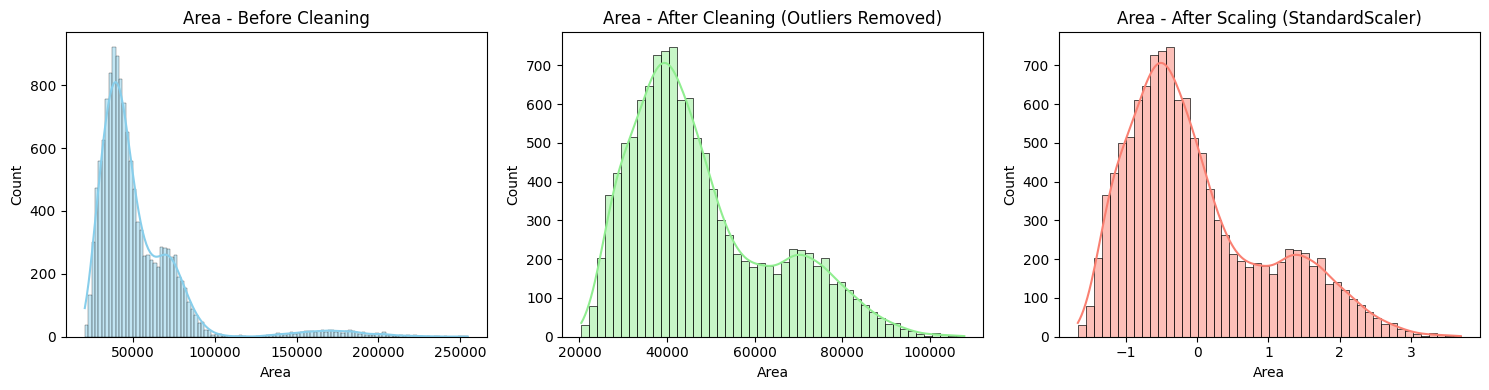

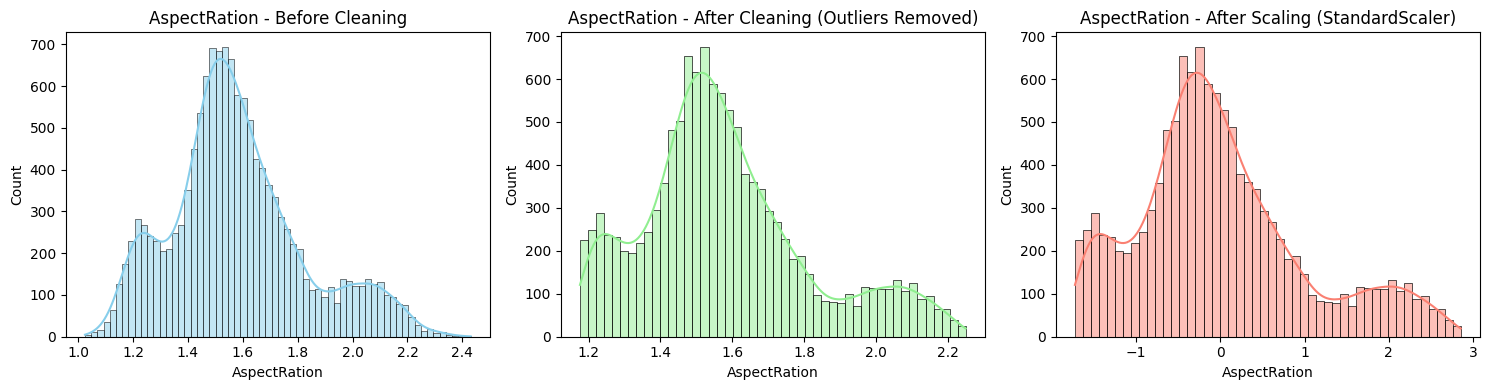

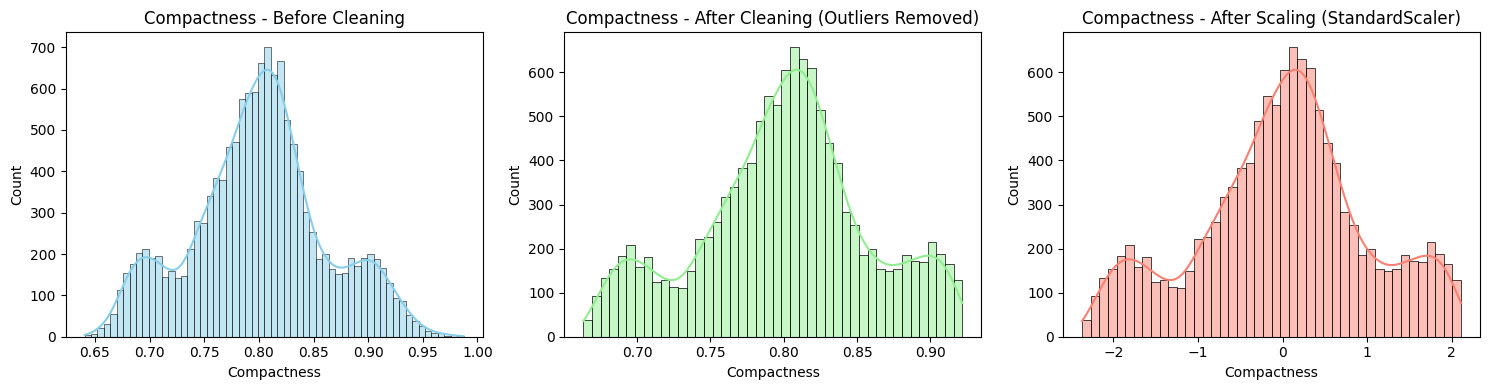

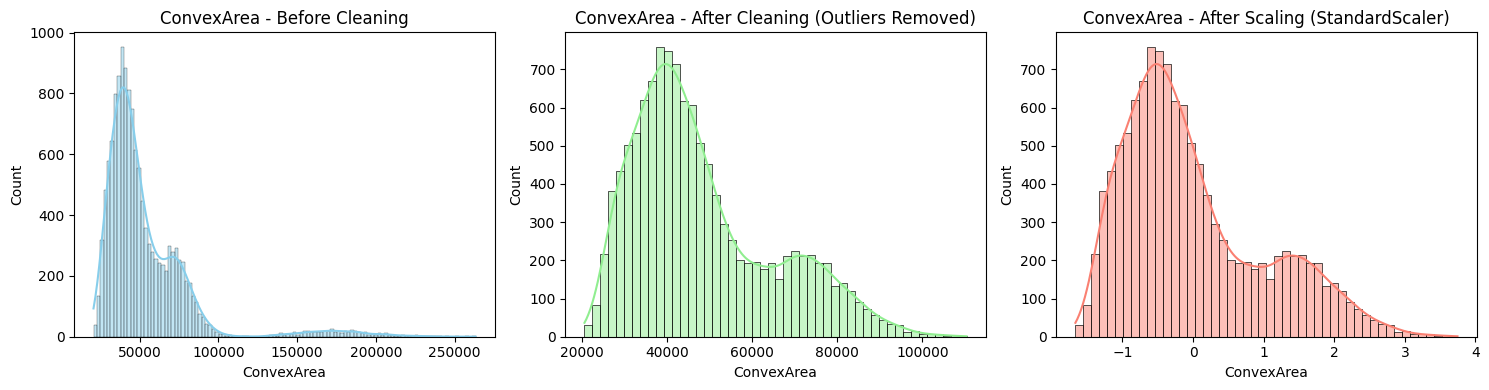

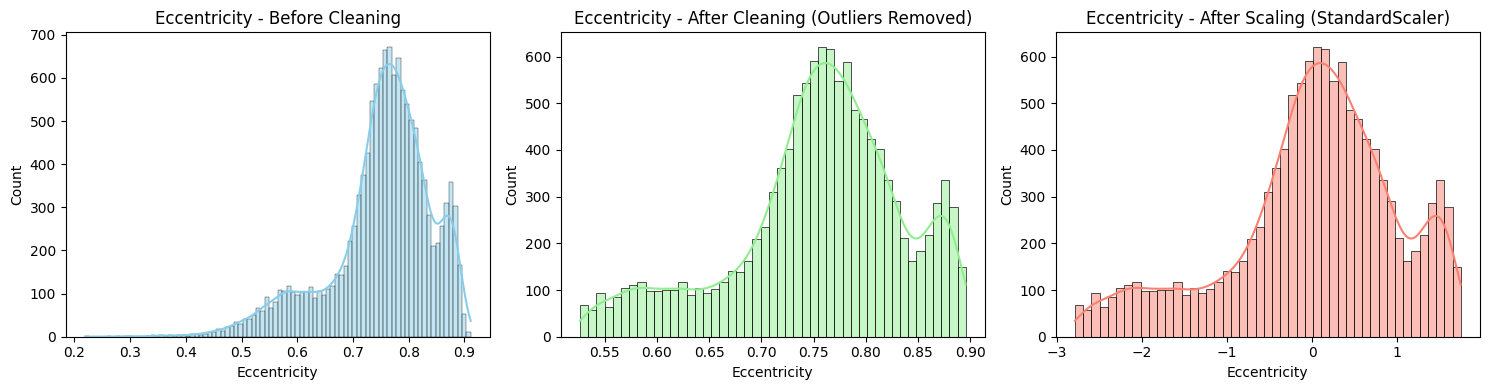

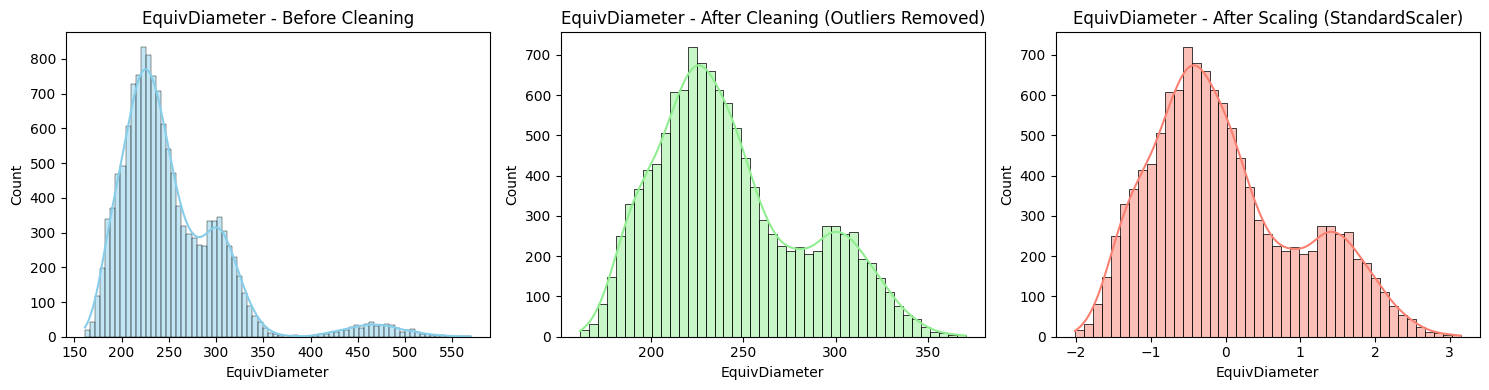

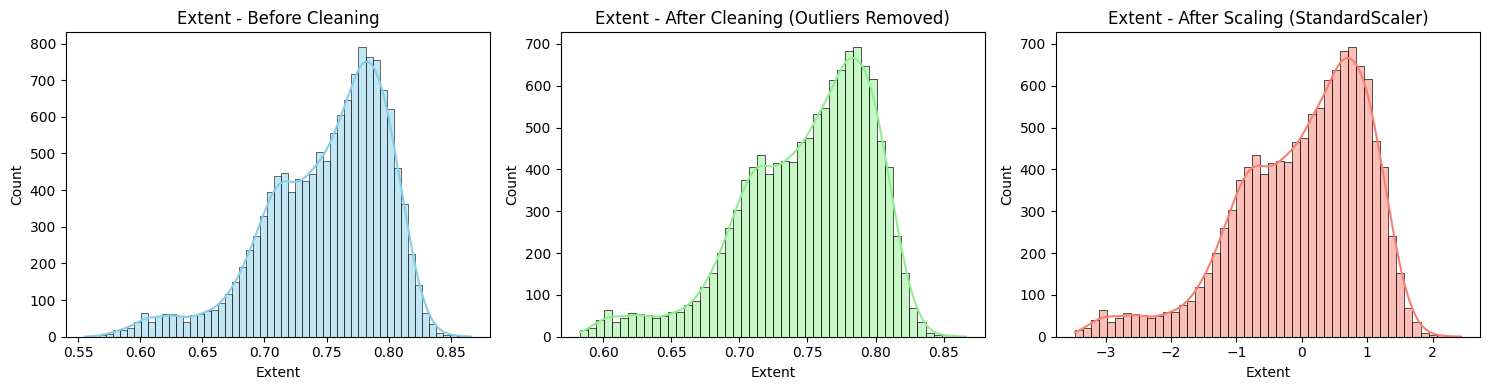

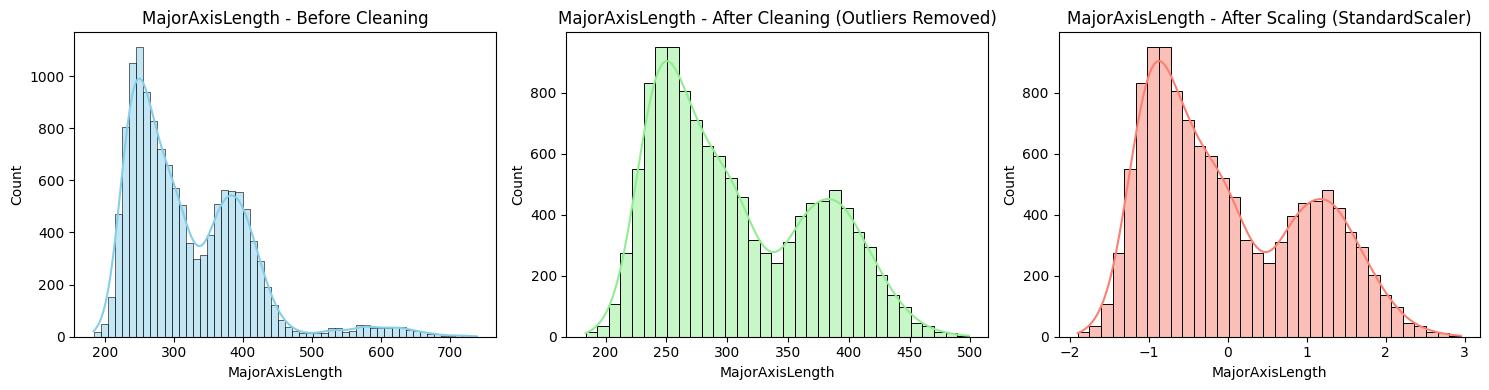

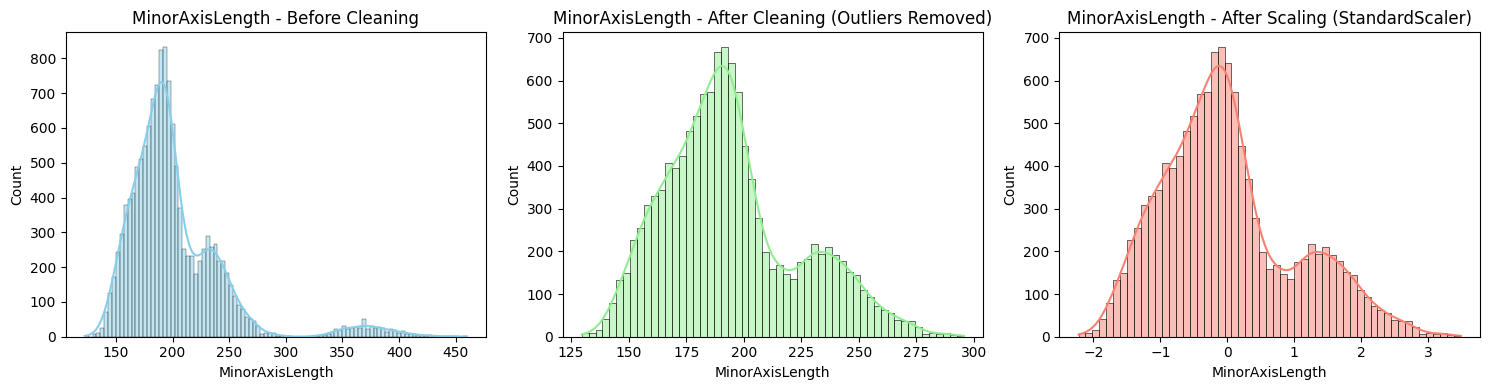

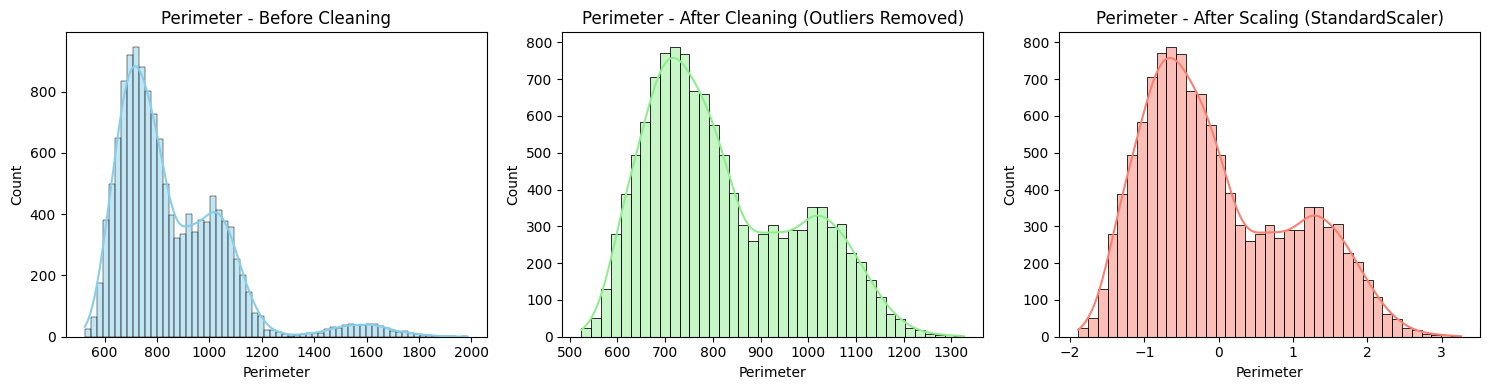

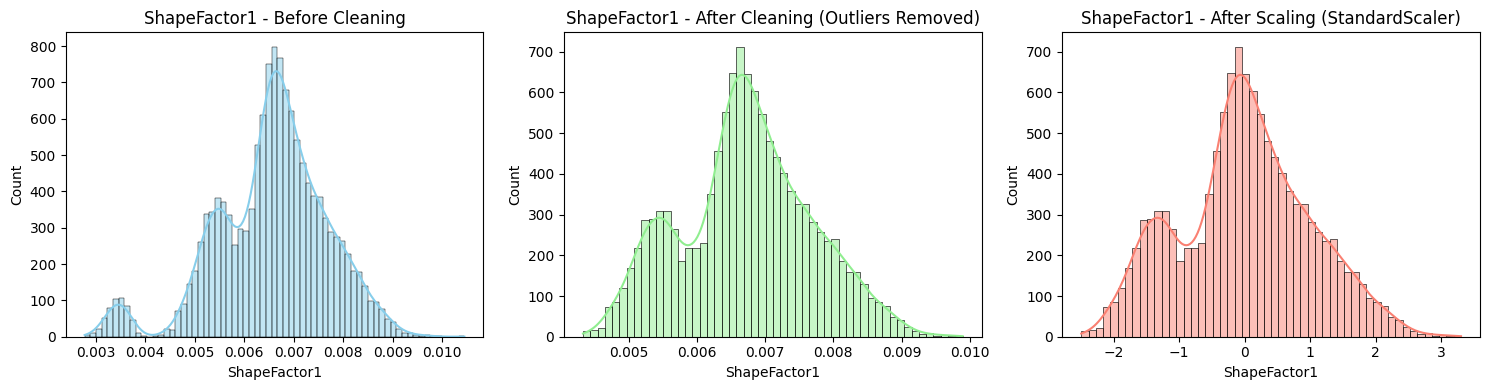

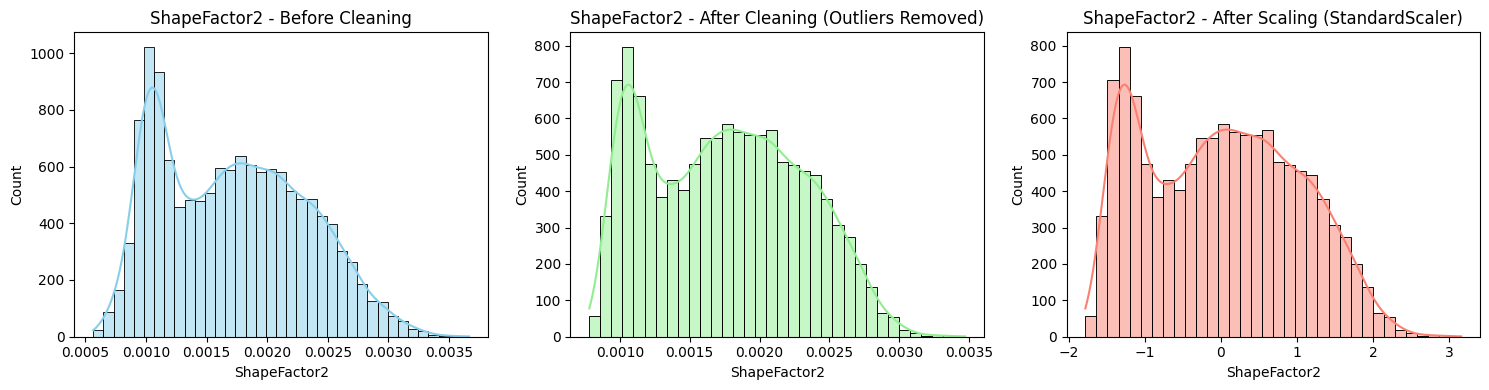

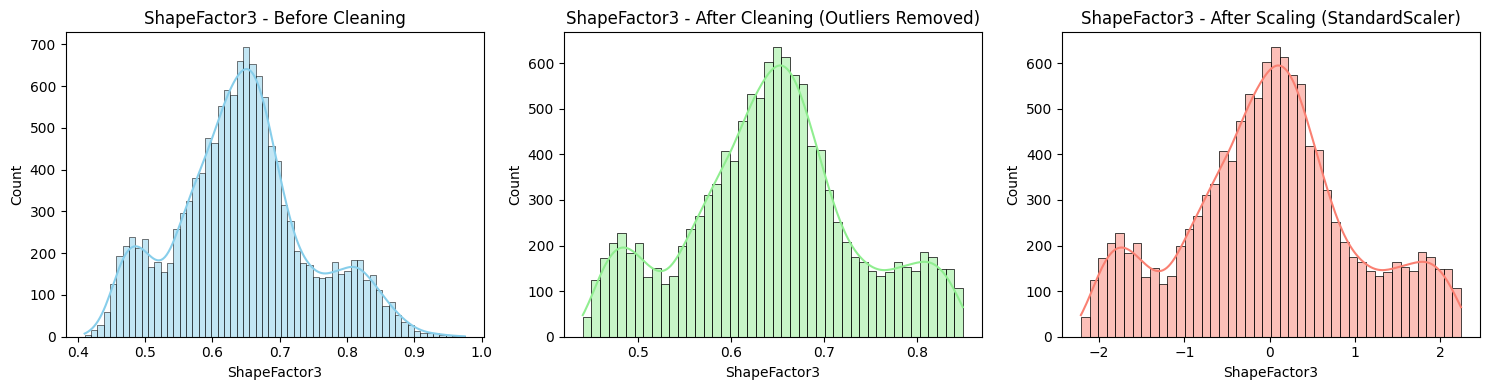

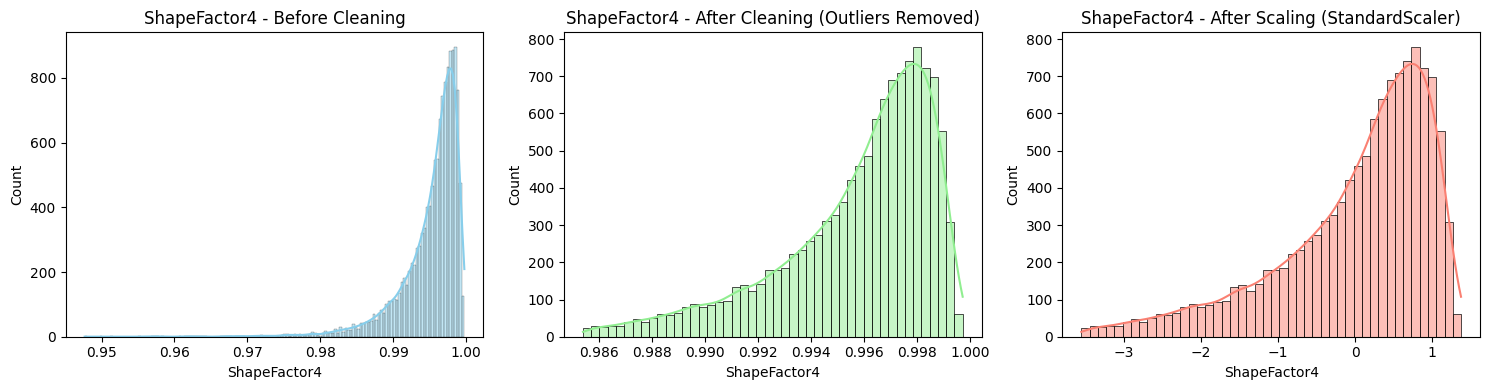

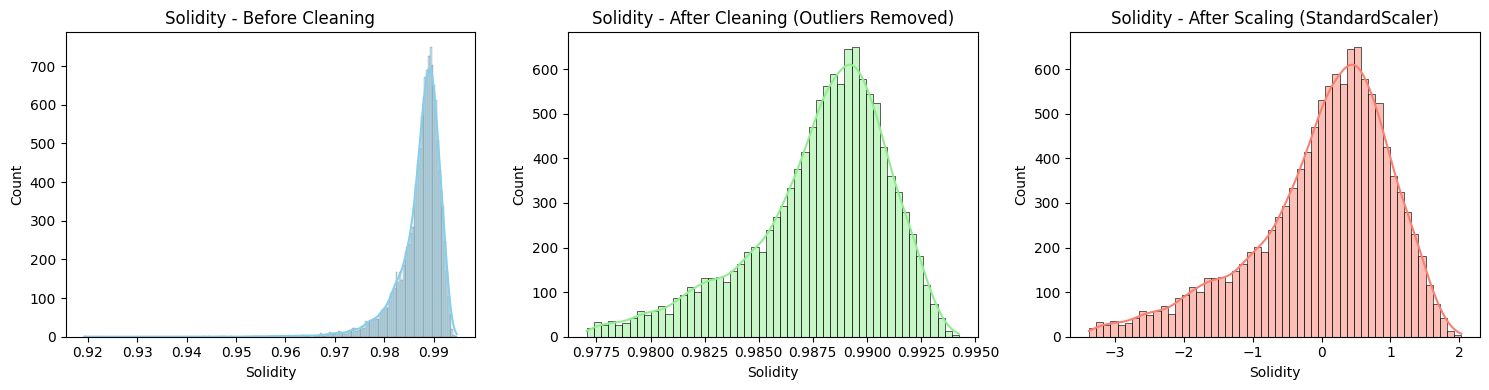

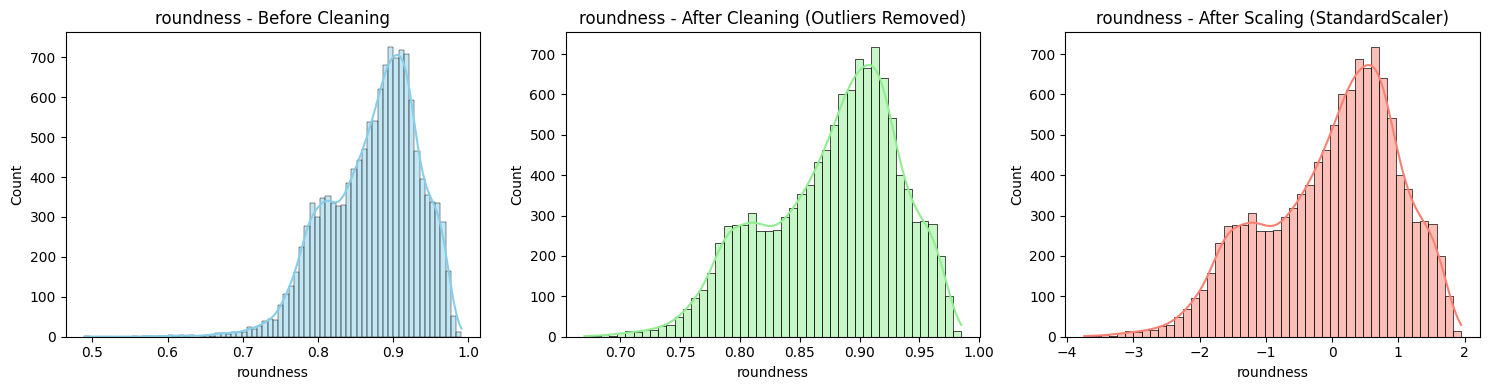

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

dataScaled_df = pd.DataFrame(data_scaled, columns=dataCleaned.columns)


for col in numeric_cols:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    sns.histplot(data[col], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f"{col} - Before Cleaning")

    sns.histplot(dataCleaned[col], kde=True, ax=axes[1], color='lightgreen')
    axes[1].set_title(f"{col} - After Cleaning (Outliers Removed)")

    sns.histplot(dataScaled_df[col], kde=True, ax=axes[2], color='salmon')
    axes[2].set_title(f"{col} - After Scaling (StandardScaler)")

    plt.tight_layout()
    plt.show()

## Feature Distribution Analysis

Before preprocessing, features such as Area and Perimeter showed right-skewed distributions with extreme outliers.
After outlier removal using the IQR method (threshold = 2×IQR), these distributions became smoother and more symmetric, indicating reduced variance from extreme values.

After applying StandardScaler, all features were standardized to have a mean of approximately 0 and a standard deviation of 1.
The scaled distributions are centered around zero and follow similar shapes as the cleaned data, preserving the relative structure of the features while normalizing their magnitudes.

Overall, preprocessing effectively reduced outlier influence and ensured consistent scaling across all numerical variables, making the dataset suitable for machine learning algorithms sensitive to feature magnitudes.

## Before Cleaning:
Many features were skewed with visible outliers (especially Area, Perimeter, and ConvexArea).

## After Cleaning:
The distributions became smoother and less skewed, with extreme values removed.

## After Scaling:
All features are now centered around zero with comparable spread, improving model stability and convergence.

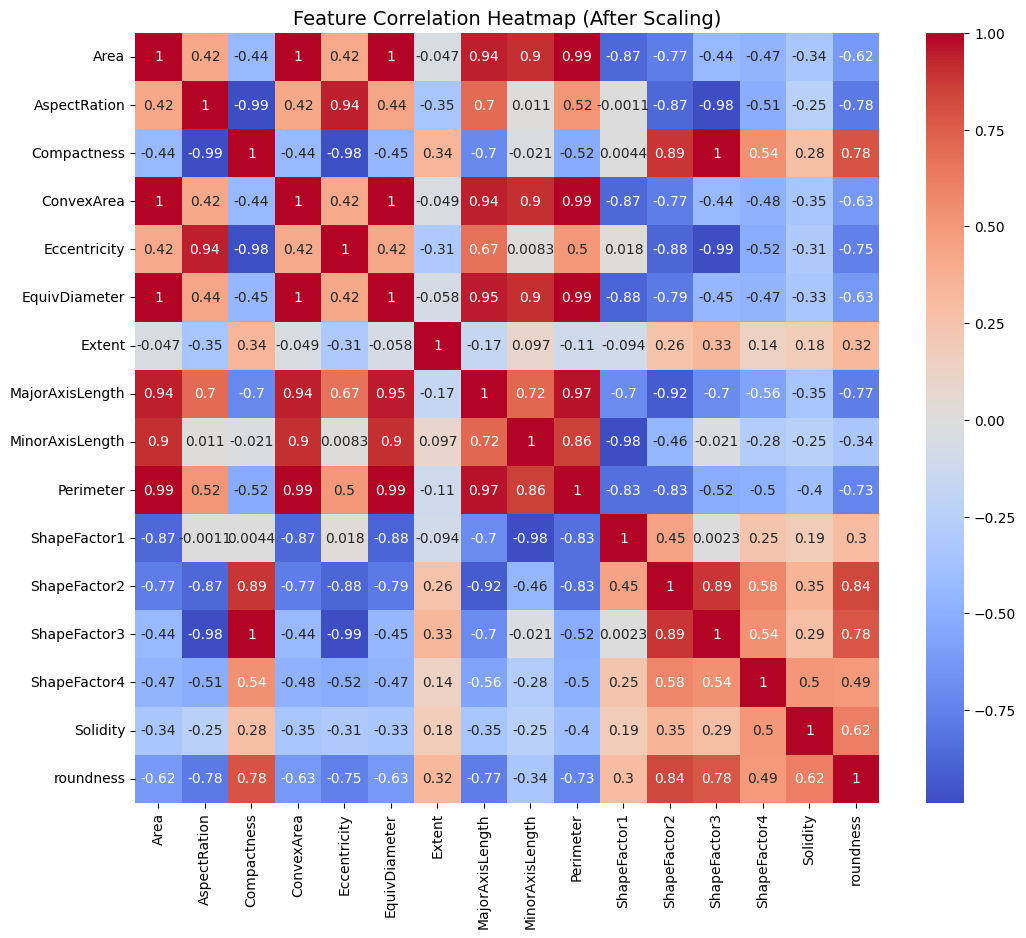

In [140]:
corr_matrix = dataScaled_df[numeric_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Feature Correlation Heatmap (After Scaling)", fontsize=14)
plt.show()

# Strong correlations

In [141]:
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

strong_corr_pairs = [
    (corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j])
    for i in range(len(corr_matrix.columns))
    for j in range(len(corr_matrix.columns))
    if (i < j) and (abs(corr_matrix.iloc[i, j]) > 0.8)
]

# Sort descending by correlation value
strong_corr_pairs = sorted(strong_corr_pairs, key=lambda x: abs(x[2]), reverse=True)

# Show results
for pair in strong_corr_pairs:
    print(pair)

('Area', 'ConvexArea', np.float64(0.9996396683166453))
('Compactness', 'ShapeFactor3', np.float64(0.9989004529468909))
('ConvexArea', 'EquivDiameter', np.float64(0.9959333004284644))
('Area', 'EquivDiameter', np.float64(0.9958977394166504))
('EquivDiameter', 'Perimeter', np.float64(0.9901246360792125))
('AspectRation', 'Compactness', np.float64(-0.9897525483907424))
('Eccentricity', 'ShapeFactor3', np.float64(-0.9867648232048878))
('ConvexArea', 'Perimeter', np.float64(0.9866510905143444))
('Area', 'Perimeter', np.float64(0.9858710612166436))
('MinorAxisLength', 'ShapeFactor1', np.float64(-0.9830793097650447))
('AspectRation', 'ShapeFactor3', np.float64(-0.9820762472839712))
('Compactness', 'Eccentricity', np.float64(-0.9782663332308325))
('MajorAxisLength', 'Perimeter', np.float64(0.9666450987038194))
('EquivDiameter', 'MajorAxisLength', np.float64(0.947560746018999))
('ConvexArea', 'MajorAxisLength', np.float64(0.9410169318065837))
('Area', 'MajorAxisLength', np.float64(0.94099759819

# PCA

In [142]:
from sklearn.decomposition import PCA

pca = PCA()
pca_result = pca.fit_transform(dataScaled_df[numeric_cols])

# Step 2: Get explained variance ratio
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Step 3: Create a DataFrame for easier interpretation
pca_variance = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(explained_variance))],
    'Explained Variance': explained_variance,
    'Cumulative Variance': cumulative_variance
})

print(pca_variance.head(10))

  Principal Component  Explained Variance  Cumulative Variance
0                 PC1            0.605756             0.605756
1                 PC2            0.227786             0.833543
2                 PC3            0.066403             0.899945
3                 PC4            0.052816             0.952761
4                 PC5            0.032598             0.985359
5                 PC6            0.007415             0.992774
6                 PC7            0.003807             0.996581
7                 PC8            0.002918             0.999499
8                 PC9            0.000408             0.999907
9                PC10            0.000037             0.999944


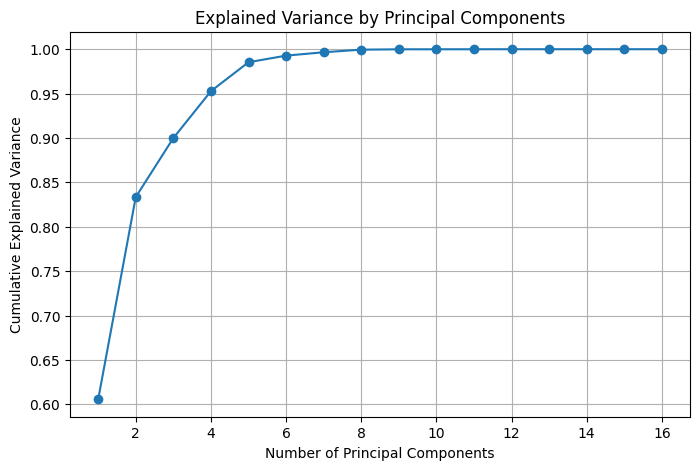

In [143]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_variance)+1), cumulative_variance, marker='o')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Principal Components')
plt.grid(True)
plt.show()

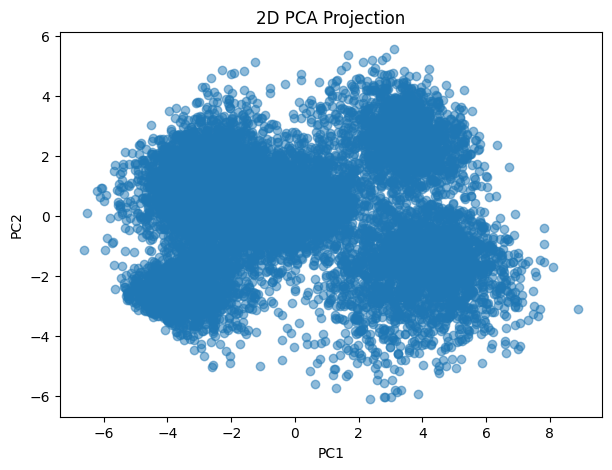

In [144]:
pca_2 = PCA(n_components=2)
pca_2_result = pca_2.fit_transform(dataScaled_df[numeric_cols])

plt.figure(figsize=(7,5))
plt.scatter(pca_2_result[:,0], pca_2_result[:,1], alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D PCA Projection')
plt.show()

In [146]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=dataScaled_df[numeric_cols].columns
)

pd.set_option('display.max_rows', None)  # show all rows
print(loadings)

                      PC1       PC2       PC3       PC4       PC5       PC6  \
Area             0.288214 -0.222674  0.053950 -0.024769 -0.013933  0.094972   
AspectRation     0.242613  0.321920  0.161163  0.015931  0.018358 -0.219878   
Compactness     -0.247704 -0.323461 -0.138152 -0.051069 -0.006522 -0.043517   
ConvexArea       0.288615 -0.222096  0.044705 -0.023136 -0.010045  0.098407   
Eccentricity     0.239872  0.324790  0.119448  0.082584  0.038460  0.435510   
EquivDiameter    0.290498 -0.219445  0.066306 -0.037888 -0.014628  0.045948   
Extent          -0.073663 -0.203737  0.255650  0.905051  0.255986 -0.048747   
MajorAxisLength  0.316021 -0.060572  0.109250 -0.017650 -0.023499 -0.032188   
MinorAxisLength  0.206610 -0.398866 -0.007254 -0.060723 -0.017811  0.057774   
Perimeter        0.302307 -0.171658  0.017683 -0.042865  0.071789 -0.109956   
ShapeFactor1    -0.197861  0.400901 -0.036839  0.088604  0.040320  0.016588   
ShapeFactor2    -0.307633 -0.110735 -0.126418 -0.011

## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) was applied to the standardized dataset to reduce its dimensionality while retaining most of the original variance.  
The first two principal components captured the majority of the dataset’s variability — **PC1 explained approximately 60.6%**, and **PC2 about 22.8%** of the total variance.  
Together, these two components accounted for nearly **83.3%** of the overall data variance.  
The cumulative variance plot indicated that around **four components** were sufficient to preserve roughly **95%** of the total variance.  

PCA not only reduced the feature space but also revealed the underlying structure of the data.  
The two-dimensional visualization of the first two components showed clear grouping patterns, suggesting that PCA effectively summarized the original correlated variables into a smaller set of uncorrelated components.  
Overall, this analysis demonstrates that dimensionality can be reduced without significant information loss, while improving interpretability and enabling clearer visualization of feature relationships.

## Final Report Summary

This project focused on comprehensive data preprocessing and analysis.  
The datasets were integrated, cleaned, scaled, and analyzed using visual and statistical methods.  
Key preprocessing steps included handling missing values, removing outliers, and feature scaling.  
Exploratory visualizations and PCA revealed important feature relationships and variance patterns.  
The workflow demonstrates how proper preprocessing improves data quality and supports further machine-learning analysis.